In [14]:
# =========================
# 1) Setup: imports + load
# =========================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
    confusion_matrix, classification_report
)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_PATH = "/Users/led7283981/Downloads/EEG.machinelearing_data_BRMH.csv"
assert os.path.exists(DATA_PATH), f"File not found: {DATA_PATH}"

df = pd.read_csv(DATA_PATH, low_memory=False)
print("Loaded shape:", df.shape)
print("Columns (first 20):", df.columns[:20].tolist())

Loaded shape: (945, 1149)
Columns (first 20): ['no.', 'sex', 'age', 'eeg.date', 'education', 'IQ', 'main.disorder', 'specific.disorder', 'AB.A.delta.a.FP1', 'AB.A.delta.b.FP2', 'AB.A.delta.c.F7', 'AB.A.delta.d.F3', 'AB.A.delta.e.Fz', 'AB.A.delta.f.F4', 'AB.A.delta.g.F8', 'AB.A.delta.h.T3', 'AB.A.delta.i.C3', 'AB.A.delta.j.Cz', 'AB.A.delta.k.C4', 'AB.A.delta.l.T4']


In [ ]:
# ==========================================
# 2) Cleanup, labels, EEG feature selection
# ==========================================
df = df.copy()
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.drop_duplicates(inplace=True)

# Add is_patient: 1 if main.disorder is anything but "Healthy control", else 0
if "main.disorder" not in df.columns:
    raise KeyError("Expected column 'main.disorder' not found in the dataset.")

df["is_patient"] = (
    df["main.disorder"].astype(str).str.strip().str.casefold() != "healthy control"
).astype("int8")

# Identify numeric EEG feature columns (exclude metadata/labels)
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
meta_numeric_candidates = ["no.", "age", "IQ", "education"]
meta_numeric = [c for c in meta_numeric_candidates if c in numeric_cols]
meta_numeric += ["is_patient"]

eeg_cols = [c for c in numeric_cols if c not in set(meta_numeric)]
print(f"Initial numeric EEG feature count: {len(eeg_cols)}")

# Remove high-missing and constant columns
max_missing_frac = 0.40
missing_frac = df[eeg_cols].isna().mean()
high_missing_cols = missing_frac[missing_frac > max_missing_frac].index.tolist()
eeg_cols = [c for c in eeg_cols if c not in high_missing_cols]

constant_cols = [c for c in eeg_cols if df[c].nunique(dropna=True) <= 1]
eeg_cols = [c for c in eeg_cols if c not in constant_cols]

print(f"EEG features after cleanup: {len(eeg_cols)} (dropped {len(high_missing_cols)} high-missing, {len(constant_cols)} constant)")

assert "is_patient" in df.columns, "Label column is missing."
assert len(eeg_cols) > 0, "No EEG features available after cleanup."

Initial numeric EEG feature count: 1141
EEG features after cleanup: 1140 (dropped 1 high-missing, 0 constant)


In [17]:
# ===================================================
# 3) EDA: Prepare PCA (for visualization-only in EDA)
#     Note: Modeling below will avoid leakage via CV.
# ===================================================
# Impute + scale EEG features (entire dataset) for EDA visuals
imputer_eda = SimpleImputer(strategy="median")
scaler_eda = StandardScaler()

X_eeg_full = df[eeg_cols].copy()
X_eeg_full_imputed = imputer_eda.fit_transform(X_eeg_full)
X_eeg_full_scaled = scaler_eda.fit_transform(X_eeg_full_imputed)

n_components_eda = int(min(100, X_eeg_full_scaled.shape[0], X_eeg_full_scaled.shape[1]))
pca_eda = PCA(n_components=n_components_eda, svd_solver="randomized", random_state=RANDOM_STATE)
X_pca_full = pca_eda.fit_transform(X_eeg_full_scaled)
pca_cols = [f"PC{i+1}" for i in range(n_components_eda)]
df_pca_full = pd.DataFrame(X_pca_full, index=df.index, columns=pca_cols)

explained = pca_eda.explained_variance_ratio_
cum_explained = np.cumsum(explained)
print(f"[EDA] PCA fitted with {n_components_eda} components. Cumulative explained variance: {cum_explained[-1]:.3f}")

[EDA] PCA fitted with 100 components. Cumulative explained variance: 0.953


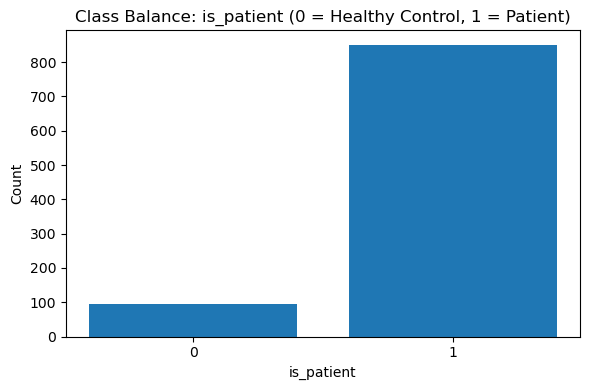

In [18]:
# ======================================
# 4) EDA Chart 1: Class balance (counts)
# ======================================
class_counts = df["is_patient"].value_counts().sort_index()
plt.figure(figsize=(6,4))
plt.bar(class_counts.index.astype(str), class_counts.values)
plt.title("Class Balance: is_patient (0 = Healthy Control, 1 = Patient)")
plt.xlabel("is_patient")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

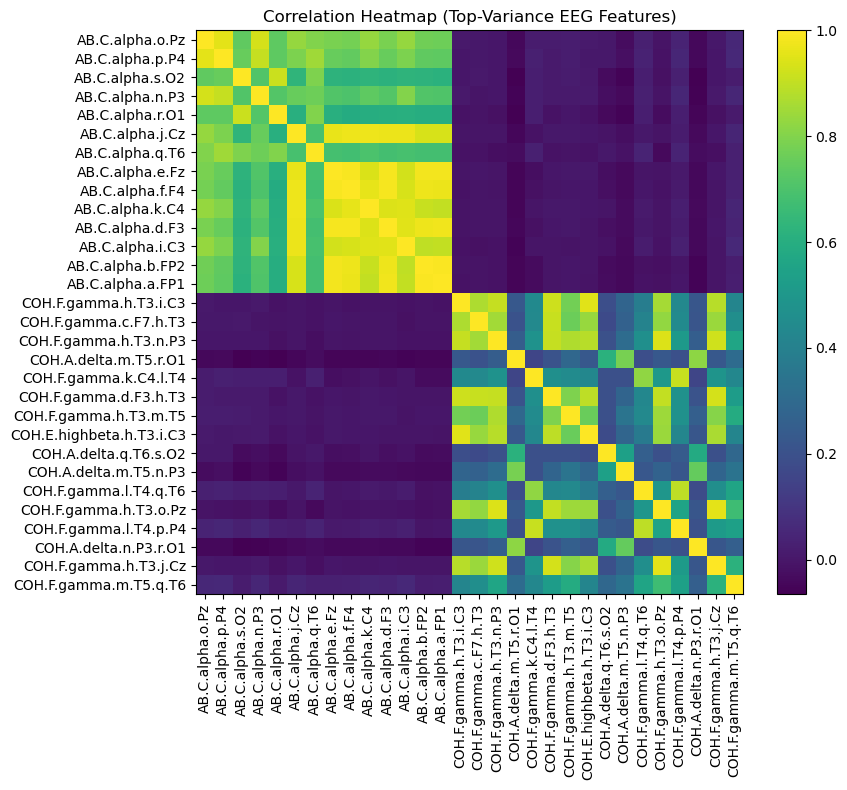

In [19]:
# ===========================================================
# 5) EDA Chart 2: Heatmap of correlations among EEG features
#     (top 30 by variance to keep it readable)
# ===========================================================
# Select top-variance EEG features for correlation inspection
variances = np.var(X_eeg_full_imputed, axis=0)
var_series = pd.Series(variances, index=eeg_cols).sort_values(ascending=False)
top_k = min(30, len(var_series))
top_features = var_series.index[:top_k].tolist()

corr_mat = pd.DataFrame(X_eeg_full_imputed, columns=eeg_cols)[top_features].corr()

plt.figure(figsize=(9,8))
plt.imshow(corr_mat.values, aspect="auto")
plt.colorbar()
plt.xticks(ticks=np.arange(len(top_features)), labels=top_features, rotation=90)
plt.yticks(ticks=np.arange(len(top_features)), labels=top_features)
plt.title("Correlation Heatmap (Top-Variance EEG Features)")
plt.tight_layout()
plt.show()

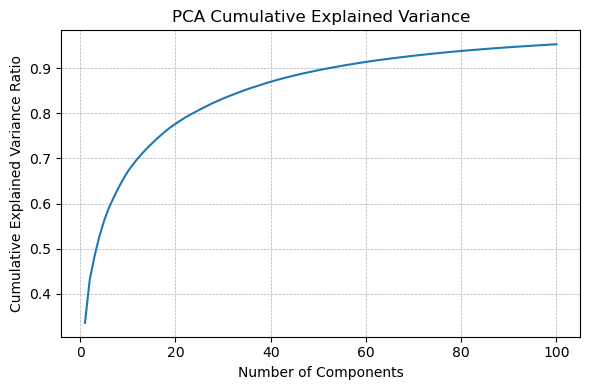

In [20]:
# =========================================================
# 6) EDA Chart 3: PCA cumulative explained variance (line)
# =========================================================
plt.figure(figsize=(6,4))
plt.plot(np.arange(1, n_components_eda+1), np.cumsum(explained))
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance Ratio")
plt.title("PCA Cumulative Explained Variance")
plt.grid(True, linestyle="--", linewidth=0.5)
plt.tight_layout()
plt.show()

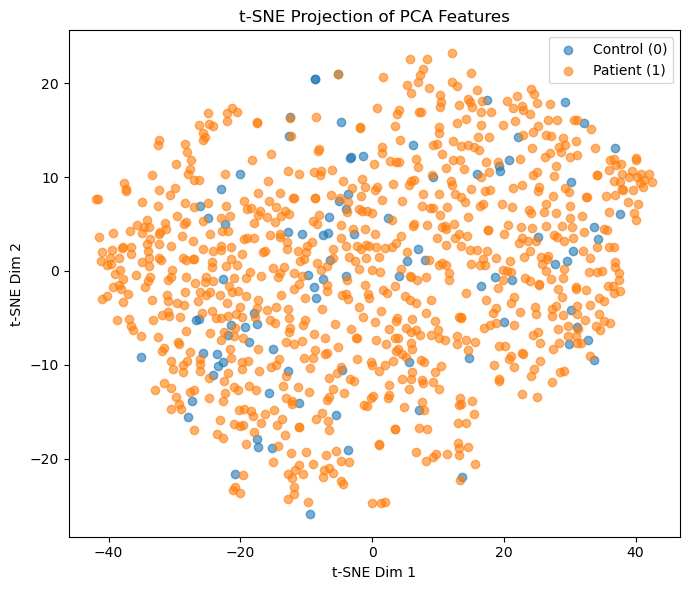

In [ ]:
# =======================================================
# 7) t-SNE of the PCA features
# =======================================================
from sklearn.manifold import TSNE

# Run t-SNE on the PCA features 
tsne = TSNE(n_components=2, random_state=42, perplexity=30, learning_rate="auto", init="pca")
X_tsne = tsne.fit_transform(df_pca_full.iloc[:, :30]) 

plt.figure(figsize=(7,6))
plt.scatter(X_tsne[mask_ctrl, 0], X_tsne[mask_ctrl, 1], label="Control (0)", alpha=0.6)
plt.scatter(X_tsne[mask_pat, 0], X_tsne[mask_pat, 1], label="Patient (1)", alpha=0.6)
plt.xlabel("t-SNE Dim 1")
plt.ylabel("t-SNE Dim 2")
plt.title("t-SNE Projection of PCA Features")
plt.legend()
plt.tight_layout()
plt.show()

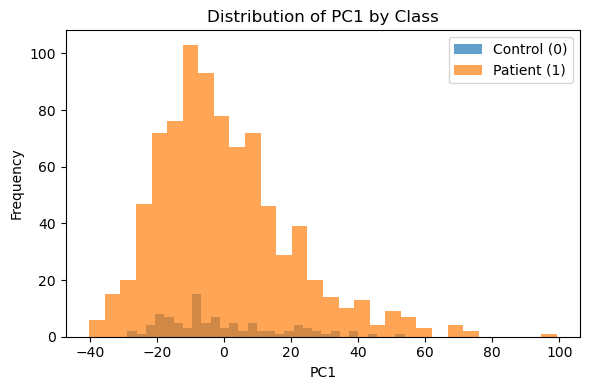

In [27]:
# =======================================================
# 8) EDA Chart 5: Distribution of PC1 by class (histogram)
# =======================================================
plt.figure(figsize=(6,4))
plt.hist(df_pca_full.loc[mask_ctrl, "PC1"], bins=30, alpha=0.7, label="Control (0)")
plt.hist(df_pca_full.loc[mask_pat, "PC1"], bins=30, alpha=0.7, label="Patient (1)")
plt.xlabel("PC1")
plt.ylabel("Frequency")
plt.title("Distribution of PC1 by Class")
plt.legend()
plt.tight_layout()
plt.show()

In [34]:
# ============================
# Step 9 — Robust Model Suite (no-stall + guaranteed fallback)
# This version:
#  - avoids Halving* complexity,
#  - trims heavy grids,
#  - guards each search so one failure won't kill the run,
#  - and GUARANTEES a fitted baseline pipeline if all CV searches fail.
# ============================
import sys, subprocess, warnings, os
warnings.filterwarnings("ignore")

# ---------- Ensure optional libs (quiet install if missing) ----------
def _ensure_pkg(mod_name, pip_name=None):
    try:
        __import__(mod_name)
        return True
    except Exception:
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", pip_name or mod_name, "--quiet"])
            __import__(mod_name)
            return True
        except Exception as e:
            print(f"[Info] Could not install {pip_name or mod_name}: {e}")
            return False

HAS_XGB  = _ensure_pkg("xgboost",  "xgboost")
HAS_LGBM = _ensure_pkg("lightgbm", "lightgbm")
HAS_CATB = _ensure_pkg("catboost","catboost")

# LightGBM: suppress chatter
os.environ["LIGHTGBM_VERBOSE"] = "-1"

# ---------- Imports ----------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV

# Optional boosters
if HAS_XGB:
    from xgboost import XGBClassifier
if HAS_LGBM:
    from lightgbm import LGBMClassifier
if HAS_CATB:
    from catboost import CatBoostClassifier

# ---------- RNG ----------
if "RANDOM_STATE" not in globals():
    RANDOM_STATE = 42

# ---------- Inputs from previous steps ----------
assert "df" in globals() and "eeg_cols" in globals() and "is_patient" in df.columns, \
    "Please run steps 1–8 first to create df, eeg_cols, and is_patient."

X = df[eeg_cols].copy()
y = df["is_patient"].astype(int).values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

# PCA components cap
n_comp_model = int(min(100, X_train.shape[1], X_train.shape[0]))

# Class imbalance (patients >> controls)
pos = int((y_train == 1).sum())
neg = int((y_train == 0).sum())
scale_pos_weight = (neg / max(pos, 1)) if pos > 0 else 1.0

# ---------- Base pipeline ----------
base_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=n_comp_model, svd_solver="randomized", random_state=RANDOM_STATE)),
    ("clf", LogisticRegression())  # placeholder
])

# ---------- Compact, reliable grids ----------
models = [
    ("LogisticRegression",
     LogisticRegression(max_iter=1000, class_weight="balanced", solver="lbfgs", random_state=RANDOM_STATE),
     {"clf__C": [0.5, 1.0, 5.0]}),

    ("LinearSVM",
     LinearSVC(class_weight="balanced", random_state=RANDOM_STATE),
     {"clf__C": [0.5, 1.0, 5.0]}),

    ("SVC_RBF",
     SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=RANDOM_STATE),
     {"clf__C": [0.5, 1.0], "clf__gamma": ["scale"]}),

    ("KNN",
     KNeighborsClassifier(),
     {"clf__n_neighbors": [7, 15]}),

    ("RandomForest",
     RandomForestClassifier(n_estimators=500, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
     {"clf__n_estimators": [500, 800], "clf__max_depth": [None, 20], "clf__min_samples_leaf": [1, 3]}),

    ("ExtraTrees",
     ExtraTreesClassifier(n_estimators=700, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
     {"clf__n_estimators": [700], "clf__max_depth": [None, 20], "clf__min_samples_leaf": [1, 3]}),

    ("GradientBoosting",
     GradientBoostingClassifier(random_state=RANDOM_STATE),
     {"clf__n_estimators": [250], "clf__learning_rate": [0.05, 0.1], "clf__max_depth": [2, 3]}),

    ("HistGradientBoosting",
     HistGradientBoostingClassifier(random_state=RANDOM_STATE),
     {"clf__max_depth": [None, 10], "clf__learning_rate": [0.05, 0.1], "clf__max_iter": [250]}),

    ("MLP",
     MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=300, random_state=RANDOM_STATE),
     {"clf__alpha": [1e-4, 1e-3]}),
]

if HAS_XGB:
    models.append(
        ("XGBoost",
         XGBClassifier(
             objective="binary:logistic",
             eval_metric="auc",
             tree_method="hist",
             random_state=RANDOM_STATE,
             n_jobs=-1,
             scale_pos_weight=scale_pos_weight,
             verbosity=0,
         ),
         {"clf__n_estimators": [500], "clf__max_depth": [3, 5],
          "clf__learning_rate": [0.05, 0.1], "clf__subsample": [0.8],
          "clf__colsample_bytree": [0.8, 1.0]})
    )

if HAS_LGBM:
    models.append(
        ("LightGBM",
         LGBMClassifier(
             objective="binary",
             random_state=RANDOM_STATE,
             class_weight="balanced",
             n_jobs=-1,
             force_row_wise=True,
             verbose=-1, verbosity=-1,
         ),
         {"clf__n_estimators": [500], "clf__num_leaves": [31],
          "clf__learning_rate": [0.05, 0.1], "clf__max_depth": [-1],
          "clf__min_child_samples": [10]})
    )

if HAS_CATB:
    models.append(
        ("CatBoost",
         CatBoostClassifier(
             loss_function="Logloss",
             eval_metric="AUC",
             random_seed=RANDOM_STATE,
             verbose=0,
             allow_writing_files=False,
             scale_pos_weight=scale_pos_weight,
         ),
         {"clf__iterations": [400], "clf__depth": [6], "clf__learning_rate": [0.05, 0.1]})
    )

# ---------- CV selection (robust to failures) ----------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

best_name, best_grid, best_score = None, None, -np.inf
all_results = []
successful_searches = 0

for name, estimator, param_grid in models:
    pipe = clone(base_pipeline)
    pipe.set_params(clf=estimator)

    search = GridSearchCV(
        pipe,
        param_grid=param_grid,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1,
        refit=True,
        verbose=0,
        error_score=np.nan  # don't crash on a model error; mark as NaN
    )

    try:
        search.fit(X_train, y_train)
        mean_auc = float(search.best_score_) if search.best_score_ is not None else np.nan
        if not np.isnan(mean_auc):
            successful_searches += 1
            print(f"{name}: best CV ROC AUC = {mean_auc:.4f} | params: {search.best_params_}")
            all_results.append((name, mean_auc, search))
            if mean_auc > best_score:
                best_name, best_grid, best_score = name, search, mean_auc
        else:
            print(f"[Info] {name} produced NaN CV score; skipping.")
    except Exception as e:
        print(f"[Warning] {name} failed during search: {e}")

# ---------- Guaranteed fallback if ALL searches failed ----------
if best_grid is None or successful_searches == 0:
    print("\n[Fallback] No successful CV searches. Fitting a baseline LogisticRegression pipeline...")
    best_name = "LogisticRegression_BASELINE"
    best_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=n_comp_model, svd_solver="randomized", random_state=RANDOM_STATE)),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", solver="lbfgs",
                                   C=1.0, random_state=RANDOM_STATE))
    ])
    best_pipeline.fit(X_train, y_train)
    best_score = np.nan
else:
    best_pipeline = best_grid.best_estimator_

print(f"\nSelected model: {best_name} (CV ROC AUC = {best_score:.4f} if available)")


LogisticRegression: best CV ROC AUC = 0.6894 | params: {'clf__C': 0.5}
LinearSVM: best CV ROC AUC = 0.6790 | params: {'clf__C': 1.0}
SVC_RBF: best CV ROC AUC = 0.7921 | params: {'clf__C': 0.5, 'clf__gamma': 'scale'}
KNN: best CV ROC AUC = 0.7359 | params: {'clf__n_neighbors': 15}
RandomForest: best CV ROC AUC = 0.8153 | params: {'clf__max_depth': None, 'clf__min_samples_leaf': 3, 'clf__n_estimators': 800}
ExtraTrees: best CV ROC AUC = 0.8126 | params: {'clf__max_depth': None, 'clf__min_samples_leaf': 3, 'clf__n_estimators': 700}
GradientBoosting: best CV ROC AUC = 0.7397 | params: {'clf__learning_rate': 0.05, 'clf__max_depth': 2, 'clf__n_estimators': 250}
HistGradientBoosting: best CV ROC AUC = 0.7730 | params: {'clf__learning_rate': 0.05, 'clf__max_depth': 10, 'clf__max_iter': 250}
MLP: best CV ROC AUC = 0.6737 | params: {'clf__alpha': 0.001}
XGBoost: best CV ROC AUC = 0.7769 | params: {'clf__colsample_bytree': 1.0, 'clf__learning_rate': 0.05, 'clf__max_depth': 5, 'clf__n_estimators':

In [35]:
# ================================================
# Step 10 — Random Forest AUC Maximization (PCA=100)
# - Two-stage tuning (Randomized -> Grid) to maximize ROC AUC
# - Keeps the same preprocessing (Impute -> Scale -> PCA -> RF)
# ================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, RandomizedSearchCV, GridSearchCV
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
    confusion_matrix, classification_report
)
from scipy.stats import randint, uniform

# --- Preconditions (from prior steps) ---
assert "df" in globals() and "eeg_cols" in globals() and "is_patient" in df.columns, \
    "Please run preprocessing steps first to create df, eeg_cols, and is_patient."

if "RANDOM_STATE" not in globals():
    RANDOM_STATE = 42

X = df[eeg_cols].copy()
y = df["is_patient"].astype(int).values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

# Cap PCA dimensionality at 100
n_comp_model = int(min(100, X_train.shape[1], X_train.shape[0]))

# ---------- Build base RF pipeline ----------
rf_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=n_comp_model, svd_solver="randomized", random_state=RANDOM_STATE)),
    ("clf", RandomForestClassifier(
        n_estimators=600,
        class_weight="balanced",   # critical due to imbalance
        random_state=RANDOM_STATE,
        n_jobs=-1,
        oob_score=False,
        bootstrap=True
    ))
])

# ---------- Stage 1: Broad RandomizedSearch ----------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rand_param_dist = {
    "clf__n_estimators": randint(400, 1200),
    "clf__max_depth": [None] + list(range(8, 33, 4)),    # None or 8..32
    "clf__min_samples_split": randint(2, 10),
    "clf__min_samples_leaf": randint(1, 6),
    "clf__max_features": ["sqrt", "log2", None, uniform(0.2, 0.6)],  # try categorical + float in (0.2,0.8)
    "clf__bootstrap": [True],  # RF default; keeps OOB option open if desired later
}

rf_rand = RandomizedSearchCV(
    rf_pipe,
    param_distributions=rand_param_dist,
    n_iter=60,                          # increase/decrease for more/less search
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1,
    refit=True
)
rf_rand.fit(X_train, y_train)

print("\n[Stage 1] RandomizedSearch best AUC:", rf_rand.best_score_)
print("[Stage 1] Best params:", rf_rand.best_params_)

# ---------- Stage 2: Narrow Grid around the best ----------
best_params = rf_rand.best_params_.copy()

# Helper to make a small neighborhood around a numeric hyperparam
def around_int(v, lo, hi):
    vals = sorted(set([int(v)] + [int(v-1), int(v+1)]))
    return [x for x in vals if lo <= x <= hi]

def around_depth(d):
    if d is None:
        return [None, 12, 16]
    pool = sorted(set([d] + [d-4, d+4]))
    return [x for x in pool if x >= 4]

def around_float_ratio(r):
    # if it's a float (0,1], create a tiny neighborhood; else return categorical directly
    if isinstance(r, float):
        step = 0.05
        vals = [max(0.1, min(1.0, r + k*step)) for k in [-1, 0, 1]]
        return sorted(set([round(x, 3) for x in vals]))
    return [r]

grid_param = {
    "clf__n_estimators": sorted(set([best_params["clf__n_estimators"]] + [best_params["clf__n_estimators"] + k*200 for k in [-1, 1] if 200 <= best_params["clf__n_estimators"] + k*200 <= 1500])),
    "clf__max_depth": around_depth(best_params["clf__max_depth"]),
    "clf__min_samples_split": around_int(best_params["clf__min_samples_split"], 2, 20),
    "clf__min_samples_leaf": around_int(best_params["clf__min_samples_leaf"], 1, 10),
    "clf__max_features": list(set(
        ([best_params["clf__max_features"]] if best_params["clf__max_features"] in ["sqrt", "log2", None] else []) +
        (around_float_ratio(best_params["clf__max_features"]) if isinstance(best_params["clf__max_features"], float) else [])
        + ["sqrt", "log2"]  # ensure we always try common robust options
    )),
    "clf__bootstrap": [True],
}

rf_grid = GridSearchCV(
    rf_rand.best_estimator_,
    param_grid=grid_param,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)
rf_grid.fit(X_train, y_train)

print("\n[Stage 2] GridSearch best AUC:", rf_grid.best_score_)
print("[Stage 2] Best params:", rf_grid.best_params_)

# Final best RF pipeline
best_rf_pipeline = rf_grid.best_estimator_
best_rf_name = "RandomForest (tuned)"


Fitting 5 folds for each of 60 candidates, totalling 300 fits

[Stage 1] RandomizedSearch best AUC: 0.8156740196078431
[Stage 1] Best params: {'clf__bootstrap': True, 'clf__max_depth': 20, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 3, 'clf__min_samples_split': 3, 'clf__n_estimators': 1083}
Fitting 5 folds for each of 162 candidates, totalling 810 fits

[Stage 2] GridSearch best AUC: 0.8157720588235294
[Stage 2] Best params: {'clf__bootstrap': True, 'clf__max_depth': 16, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 3, 'clf__min_samples_split': 2, 'clf__n_estimators': 1083}


In [36]:
# ================================================
# Step 11 — Test-set performance (tuned Random Forest)
# ================================================
y_pred = best_rf_pipeline.predict(X_test)

# For AUC/AP we need probabilities
if hasattr(best_rf_pipeline, "predict_proba"):
    y_proba = best_rf_pipeline.predict_proba(X_test)[:, 1]
else:
    # RF exposes predict_proba; this is a fallback guard
    y_proba = y_pred.astype(float)

acc      = accuracy_score(y_test, y_pred)
prec     = precision_score(y_test, y_pred, zero_division=0)
rec      = recall_score(y_test, y_pred, zero_division=0)
f1       = f1_score(y_test, y_pred, zero_division=0)
bal_acc  = balanced_accuracy_score(y_test, y_pred)
roc_auc  = roc_auc_score(y_test, y_proba)
avg_prec = average_precision_score(y_test, y_proba)

print("=== Test Metrics (Tuned Random Forest) ===")
print(f"Accuracy:           {acc:.4f}")
print(f"Precision:          {prec:.4f}")
print(f"Recall:             {rec:.4f}")
print(f"F1-score:           {f1:.4f}")
print(f"Balanced Accuracy:  {bal_acc:.4f}")
print(f"ROC AUC:            {roc_auc:.4f}")
print(f"Average Precision:  {avg_prec:.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred, digits=4))

=== Test Metrics (Tuned Random Forest) ===
Accuracy:           0.8995
Precision:          0.8995
Recall:             1.0000
F1-score:           0.9471
Balanced Accuracy:  0.5000
ROC AUC:            0.6424
Average Precision:  0.9374

Classification Report:
               precision    recall  f1-score   support

           0     0.0000    0.0000    0.0000        19
           1     0.8995    1.0000    0.9471       170

    accuracy                         0.8995       189
   macro avg     0.4497    0.5000    0.4735       189
weighted avg     0.8090    0.8995    0.8519       189



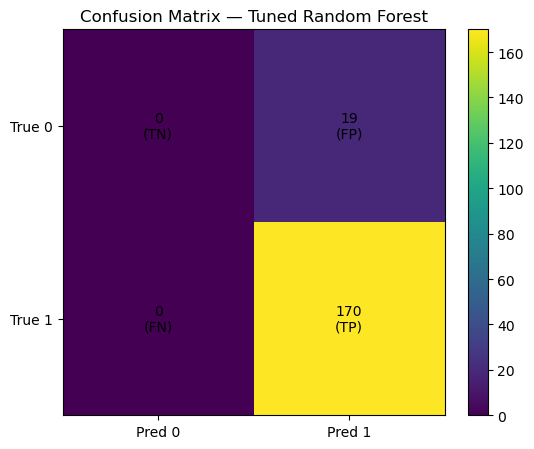

In [37]:
# ================================================
# Step 12 — Confusion Matrix (tuned Random Forest)
# ================================================
cm = confusion_matrix(y_test, y_pred, labels=[0,1])
labels = np.array([["TN", "FP"], ["FN", "TP"]])

plt.figure(figsize=(5.6,4.6))
plt.imshow(cm, aspect="auto")
plt.title("Confusion Matrix — Tuned Random Forest")
plt.colorbar()
plt.xticks([0,1], ["Pred 0","Pred 1"])
plt.yticks([0,1], ["True 0","True 1"])
for (i, j), val in np.ndenumerate(cm):
    plt.text(j, i, f"{val}\n({labels[i,j]})", ha="center", va="center")
plt.tight_layout()
plt.show()

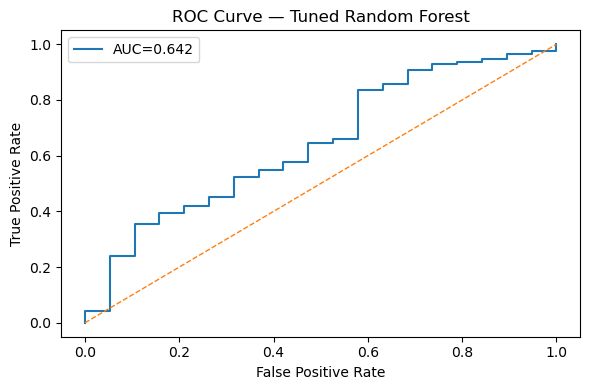

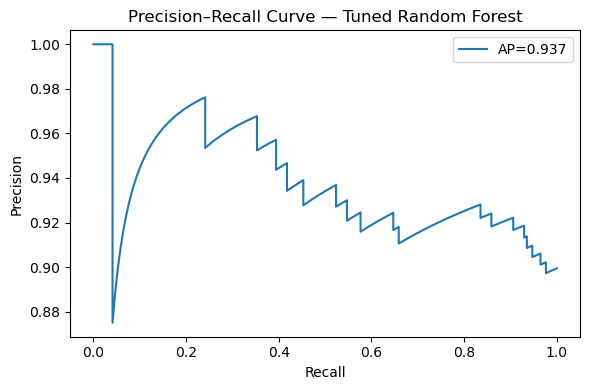

In [38]:
# ================================================
# Step 13 — ROC Curve & PR Curve (tuned Random Forest)
# ================================================
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f"AUC={roc_auc:.3f}")
plt.plot([0,1],[0,1],"--", linewidth=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Tuned Random Forest")
plt.legend()
plt.tight_layout()
plt.show()

prec_curve, rec_curve, _ = precision_recall_curve(y_test, y_proba)
plt.figure(figsize=(6,4))
plt.plot(rec_curve, prec_curve, label=f"AP={avg_prec:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve — Tuned Random Forest")
plt.legend()
plt.tight_layout()
plt.show()

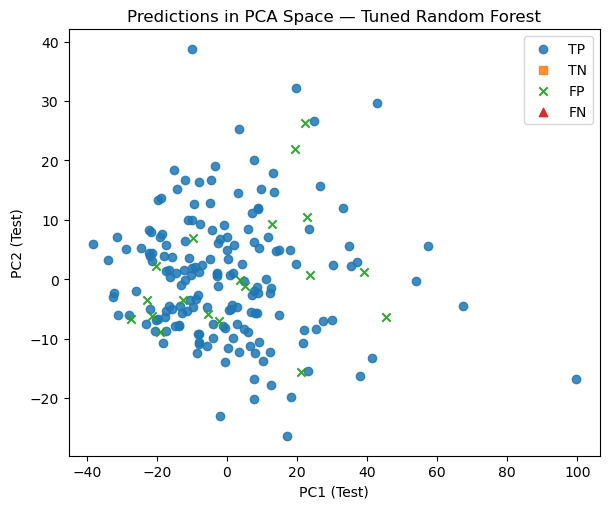

In [39]:
# ================================================
# Step 14 — PC Space Visualization (TP/TN/FP/FN)
# ================================================
p_imputer = best_rf_pipeline.named_steps["imputer"]
p_scaler  = best_rf_pipeline.named_steps["scaler"]
p_pca     = best_rf_pipeline.named_steps["pca"]

X_test_imputed = p_imputer.transform(X_test)
X_test_scaled  = p_scaler.transform(X_test_imputed)
X_test_pca     = p_pca.transform(X_test_scaled)

pc1, pc2 = X_test_pca[:, 0], X_test_pca[:, 1]

tp = (y_test == 1) & (y_pred == 1)
tn = (y_test == 0) & (y_pred == 0)
fp = (y_test == 0) & (y_pred == 1)
fn = (y_test == 1) & (y_pred == 0)

plt.figure(figsize=(6.2,5.2))
plt.scatter(pc1[tp], pc2[tp], marker="o", alpha=0.85, label="TP")
plt.scatter(pc1[tn], pc2[tn], marker="s", alpha=0.85, label="TN")
plt.scatter(pc1[fp], pc2[fp], marker="x", alpha=0.95, label="FP")
plt.scatter(pc1[fn], pc2[fn], marker="^", alpha=0.95, label="FN")
plt.xlabel("PC1 (Test)")
plt.ylabel("PC2 (Test)")
plt.title("Predictions in PCA Space — Tuned Random Forest")
plt.legend()
plt.tight_layout()
plt.show()

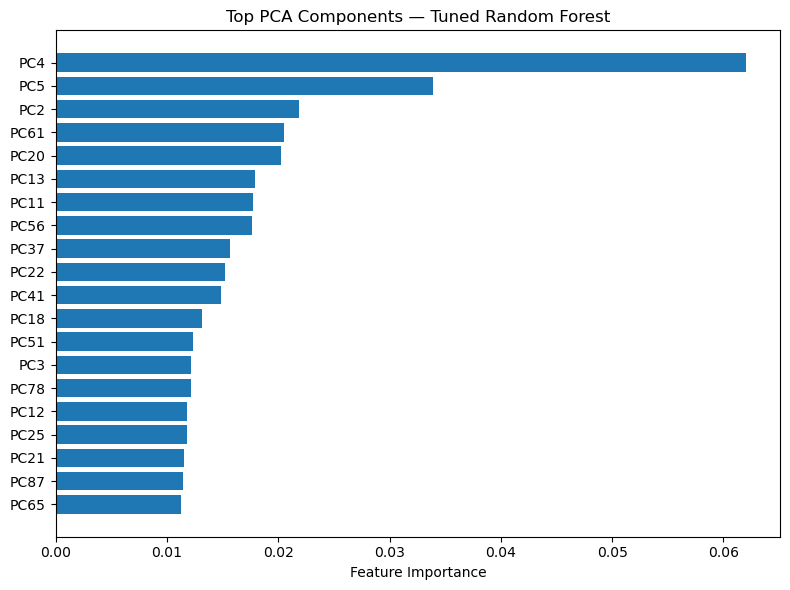

In [40]:
# ================================================
# Step 15 — PCA Feature Importance (from RF on PCs)
# ================================================
rf = best_rf_pipeline.named_steps["clf"]
pc_labels = [f"PC{i+1}" for i in range(p_pca.n_components_)]

importances = rf.feature_importances_
order = np.argsort(importances)[::-1]
top_k = min(20, len(importances))
top_idx = order[:top_k]

plt.figure(figsize=(8,6))
plt.barh(range(top_k), importances[top_idx][::-1])
plt.yticks(range(top_k), [pc_labels[i] for i in top_idx][::-1])
plt.xlabel("Feature Importance")
plt.title("Top PCA Components — Tuned Random Forest")
plt.tight_layout()
plt.show()

[Step 24] SHAP method: TreeExplainer; eval_n=189, bg_n=300, PCs=100


<Figure size 800x600 with 0 Axes>

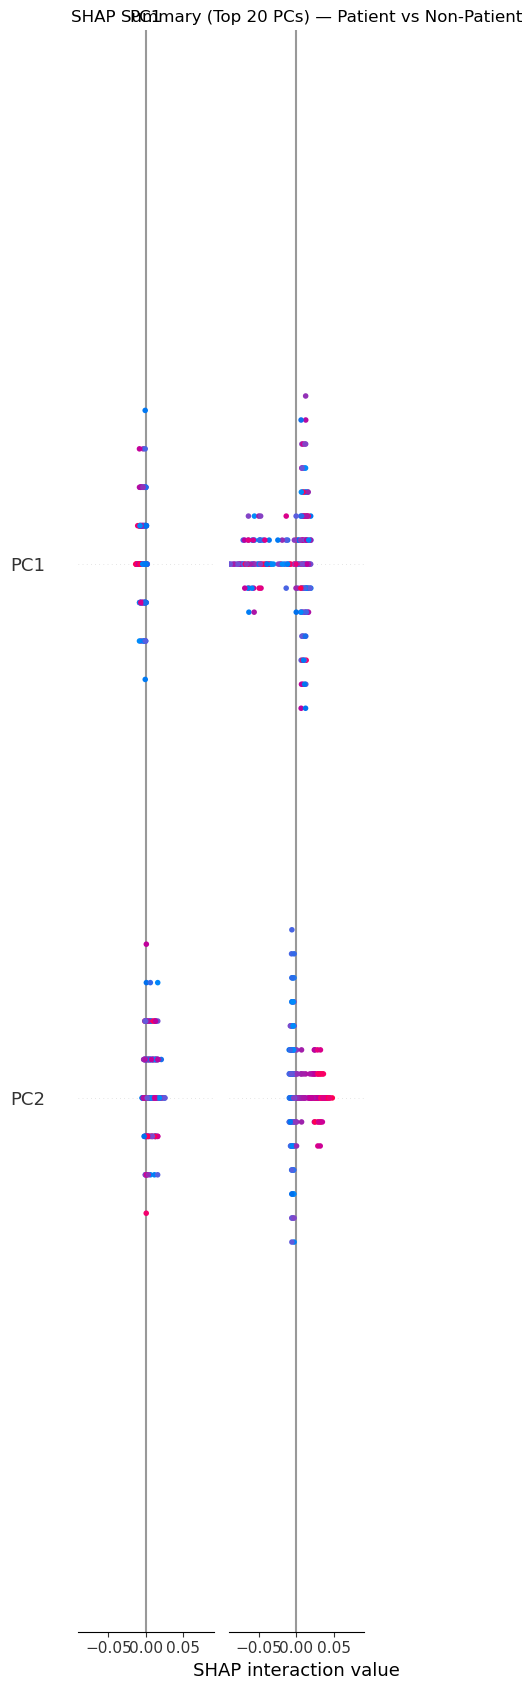

<Figure size 800x600 with 0 Axes>

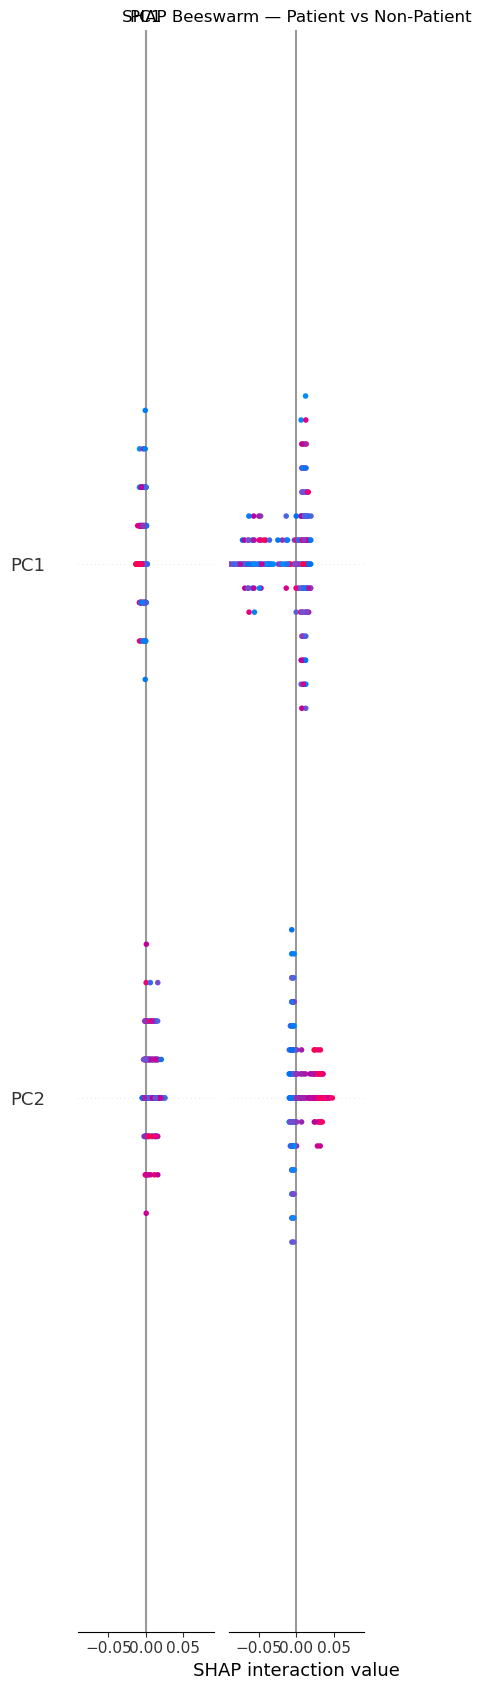

In [ ]:
# ================================================================
# Step 16 — SHAP on Principal Components (Patient vs. Non-Patient)
# - Reuses tuned RF pipeline if available; otherwise fits a quick RF
# - Computes SHAP on PCA inputs
# - Produces SHAP Summary (bar) + SHAP Beeswarm plots
# ================================================================
import sys, subprocess, warnings
warnings.filterwarnings("ignore")

# Ensure SHAP is available
try:
    import shap  # type: ignore
except Exception:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "shap", "--quiet"])
    import shap  # type: ignore

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# ------------------------------------------------
# Preconditions
# ------------------------------------------------
assert "df" in globals(), "DataFrame `df` not found — run earlier preprocessing."
assert "eeg_cols" in globals(), "`eeg_cols` not found — run earlier preprocessing."

if "RANDOM_STATE" not in globals():
    RANDOM_STATE = 42

# If is_patient not present, derive from main.disorder (anything but Healthy/Control/HC = 1)
if "is_patient" not in df.columns:
    assert "main.disorder" in df.columns, "`main.disorder` column missing; cannot derive is_patient."
    md = df["main.disorder"].astype(str).str.strip().str.lower()
    is_hc = md.str.contains("healthy") | md.str.contains(r"\bhc\b") | md.str.contains("control")
    df["is_patient"] = (~is_hc).astype(int)

# ------------------------------------------------
# Use existing tuned patient-vs-control RF pipeline if available,
# else fit a quick RandomForest pipeline now.
# ------------------------------------------------
def get_or_fit_patient_pipeline():
    # Reuse tuned RF pipeline if user ran Steps 10–16
    if "best_rf_pipeline" in globals():
        # Ensure it was trained for is_patient (not per-disorder)
        # We assume the earlier steps used df[eeg_cols] -> is_patient
        return best_rf_pipeline, None  # data tuple not needed
    
    # Fallback: fit a quick RF pipeline
    X = df[eeg_cols].copy()
    y = df["is_patient"].astype(int).values
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
    )
    n_comp = int(min(100, X_tr.shape[1], X_tr.shape[0]))
    pipe = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler",  StandardScaler()),
        ("pca",     PCA(n_components=n_comp, svd_solver="randomized", random_state=RANDOM_STATE)),
        ("clf",     RandomForestClassifier(
            n_estimators=800,
            max_depth=None,
            min_samples_leaf=1,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
    pipe.fit(X_tr, y_tr)
    return pipe, (X_tr, X_te)

patient_pipe, data_tuple = get_or_fit_patient_pipeline()

# ------------------------------------------------
# Transform to PCA space used by the model
# ------------------------------------------------
def to_pca_frames(pipe, X_tr, X_te):
    pim = pipe.named_steps["imputer"]
    psc = pipe.named_steps["scaler"]
    pca = pipe.named_steps["pca"]
    X_tr_pca = pca.transform(psc.transform(pim.transform(X_tr)))
    X_te_pca = pca.transform(psc.transform(pim.transform(X_te)))
    labels = [f"PC{i+1}" for i in range(pca.n_components_)]
    return pd.DataFrame(X_tr_pca, columns=labels), pd.DataFrame(X_te_pca, columns=labels), pca

# If we reused a prefit pipeline, build a fresh split for SHAP background/eval
if data_tuple is None:
    X = df[eeg_cols].copy()
    y = df["is_patient"].astype(int).values
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
    )
else:
    X_tr, X_te = data_tuple

X_tr_pca_df, X_te_pca_df, pca = to_pca_frames(patient_pipe, X_tr, X_te)

# Sample for speed/clarity
eval_df = X_te_pca_df.sample(n=min(500, len(X_te_pca_df)), random_state=RANDOM_STATE)
bg_df   = X_tr_pca_df.sample(n=min(300, len(X_tr_pca_df)), random_state=RANDOM_STATE)

clf = patient_pipe.named_steps["clf"]

# Prefer TreeExplainer for RandomForest; fallback to KernelExplainer if needed
try:
    explainer = shap.TreeExplainer(clf, feature_perturbation="interventional")
    sv = explainer.shap_values(eval_df)
    # If list of class-wise SHAP arrays returned, select index 1 for "patient" class
    shap_vals = sv[1] if isinstance(sv, list) and len(sv) >= 2 else sv
    method_used = "TreeExplainer"
except Exception:
    f = (lambda X_: clf.predict_proba(X_)[:, 1]) if hasattr(clf, "predict_proba") \
        else (lambda X_: clf.decision_function(X_))
    explainer = shap.KernelExplainer(f, bg_df, link="logit")
    shap_vals = explainer.shap_values(eval_df, nsamples=300)
    method_used = "KernelExplainer"

print(f"[Step 24] SHAP method: {method_used}; eval_n={len(eval_df)}, bg_n={len(bg_df)}, PCs={eval_df.shape[1]}")

# ------------------------------------------------
# SHAP Summary (Top 20 PCs) + Beeswarm for Patient vs Non-Patient
# ------------------------------------------------
plt.figure(figsize=(8,6))
shap.summary_plot(shap_vals, eval_df, plot_type="bar", max_display=20, show=False)
plt.title("SHAP Summary (Top 20 PCs) — Patient vs Non-Patient")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,6))
shap.summary_plot(shap_vals, eval_df, max_display=20, show=False)
plt.title("SHAP Beeswarm — Patient vs Non-Patient")
plt.tight_layout()
plt.show()


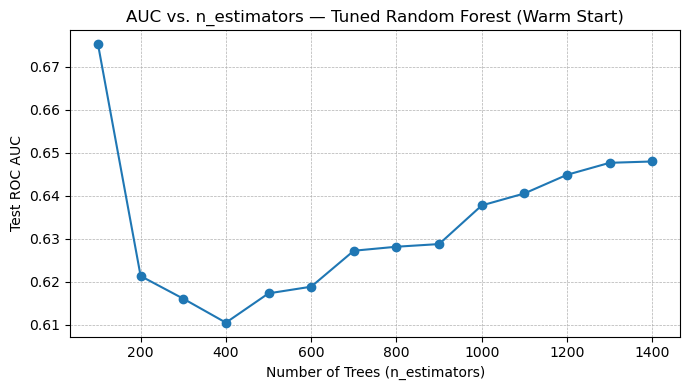

Max AUC across sweep: 0.6752321981424149 at n_estimators = 100


In [ ]:
# ================================================
# Step 17 — (Optional) n_estimators Curve @ best hyperparams
# Evaluate AUC vs number of trees using warm_start to confirm
# where performance saturates (helps avoid over/under-fitting).
# ================================================
best_params = rf_grid.best_params_.copy()  # from Step 10 Stage 2
# Build a fresh RF with the BEST hyperparams (except n_estimators will sweep)
base_rf = RandomForestClassifier(
    n_estimators=10,  # will grow
    max_depth=best_params["clf__max_depth"],
    min_samples_split=best_params["clf__min_samples_split"],
    min_samples_leaf=best_params["clf__min_samples_leaf"],
    max_features=best_params["clf__max_features"],
    bootstrap=best_params["clf__bootstrap"],
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    warm_start=True,
)

# Precompute PCA-transformed train/test for fast sweeping
X_train_pca = p_pca.transform(p_scaler.transform(p_imputer.transform(X_train)))
X_test_pca  = p_pca.transform(p_scaler.transform(p_imputer.transform(X_test)))

trees_list = list(range(100, 1401, 100))
auc_list = []
for n in trees_list:
    base_rf.set_params(n_estimators=n)
    base_rf.fit(X_train_pca, y_train)
    yprob = base_rf.predict_proba(X_test_pca)[:, 1]
    auc_list.append(roc_auc_score(y_test, yprob))

plt.figure(figsize=(7,4))
plt.plot(trees_list, auc_list, marker="o")
plt.xlabel("Number of Trees (n_estimators)")
plt.ylabel("Test ROC AUC")
plt.title("AUC vs. n_estimators — Tuned Random Forest (Warm Start)")
plt.grid(True, linestyle="--", linewidth=0.5)
plt.tight_layout()
plt.show()

print("Max AUC across sweep:", np.max(auc_list), "at n_estimators =", trees_list[int(np.argmax(auc_list))])

In [ ]:
# ============================================================
# Step 18 (REVISED, NON-BLOCKING) — Helpers for One-vs-Rest Modeling per main.disorder
#  - NO pip installs (to avoid environment hangs)
#  - Gracefully skips XGBoost/LightGBM/CatBoost if not available
#  - Adds quick sanity prints so you see it actually ran
#  - Provides helper funcs used by Step 19
# ============================================================
import warnings, os
warnings.filterwarnings("ignore")

# ---------- Optional boosters (import-only; no installs here) ----------
HAS_XGB = HAS_LGBM = HAS_CATB = False
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except Exception:
    pass

try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
    os.environ["LIGHTGBM_VERBOSE"] = "-1"  # suppress chatter
except Exception:
    pass

try:
    from catboost import CatBoostClassifier
    HAS_CATB = True
except Exception:
    pass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
    roc_auc_score, precision_recall_curve, average_precision_score, classification_report,
    confusion_matrix, roc_curve
)

# ---------- Globals / sanity checks ----------
if "RANDOM_STATE" not in globals():
    RANDOM_STATE = 42

assert "df" in globals(), "DataFrame `df` not found — run the earlier preprocessing cells first."
assert "eeg_cols" in globals(), "`eeg_cols` not found — run the earlier preprocessing cells first."
assert "main.disorder" in df.columns, "`main.disorder` column missing in df."

# Quick summary so you know this cell executed:
_cond_counts = df["main.disorder"].astype(str).str.strip().value_counts(dropna=False)
print("[Step 18] Detected main.disorder distribution:")
print(_cond_counts.to_string())

print("\n[Step 18] Optional model availability:",
      f"XGBoost={'Yes' if HAS_XGB else 'No'};",
      f"LightGBM={'Yes' if HAS_LGBM else 'No'};",
      f"CatBoost={'Yes' if HAS_CATB else 'No'}")

# ---------- Model builder ----------
def build_models(scale_pos_weight=1.0, random_state=RANDOM_STATE):
    """
    Returns a list of (name, estimator, param_grid) tuples.
    Trimmed grids to keep runtime reasonable and avoid stalls.
    """
    models = [
        ("LogisticRegression",
         LogisticRegression(max_iter=1000, class_weight="balanced", solver="lbfgs", random_state=random_state),
         {"clf__C": [0.5, 1.0, 5.0]}),

        ("LinearSVM",
         LinearSVC(class_weight="balanced", random_state=random_state),
         {"clf__C": [0.5, 1.0, 5.0]}),

        ("SVC_RBF",
         SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=random_state),
         {"clf__C": [0.5, 1.0], "clf__gamma": ["scale"]}),

        ("KNN",
         KNeighborsClassifier(),
         {"clf__n_neighbors": [7, 15]}),

        ("RandomForest",
         RandomForestClassifier(n_estimators=500, class_weight="balanced", random_state=random_state, n_jobs=-1),
         {"clf__n_estimators": [500, 800], "clf__max_depth": [None, 20], "clf__min_samples_leaf": [1, 3]}),

        ("ExtraTrees",
         ExtraTreesClassifier(n_estimators=700, class_weight="balanced", random_state=random_state, n_jobs=-1),
         {"clf__n_estimators": [700], "clf__max_depth": [None, 20], "clf__min_samples_leaf": [1, 3]}),

        ("GradientBoosting",
         GradientBoostingClassifier(random_state=random_state),
         {"clf__n_estimators": [250], "clf__learning_rate": [0.05, 0.1], "clf__max_depth": [2, 3]}),

        ("HistGradientBoosting",
         HistGradientBoostingClassifier(random_state=random_state),
         {"clf__max_depth": [None, 10], "clf__learning_rate": [0.05, 0.1], "clf__max_iter": [250]}),

        ("MLP",
         MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=300, random_state=random_state),
         {"clf__alpha": [1e-4, 1e-3]}),
    ]

    if HAS_XGB:
        models.append(
            ("XGBoost",
             XGBClassifier(
                 objective="binary:logistic",
                 eval_metric="auc",
                 tree_method="hist",
                 random_state=random_state,
                 n_jobs=-1,
                 scale_pos_weight=scale_pos_weight,
                 verbosity=0,
             ),
             {"clf__n_estimators": [500], "clf__max_depth": [3, 5],
              "clf__learning_rate": [0.05, 0.1], "clf__subsample": [0.8],
              "clf__colsample_bytree": [0.8, 1.0]})
        )

    if HAS_LGBM:
        models.append(
            ("LightGBM",
             LGBMClassifier(
                 objective="binary",
                 random_state=random_state,
                 class_weight="balanced",
                 n_jobs=-1,
                 force_row_wise=True,
                 verbose=-1, verbosity=-1,
             ),
             {"clf__n_estimators": [500], "clf__num_leaves": [31],
              "clf__learning_rate": [0.05, 0.1], "clf__max_depth": [-1],
              "clf__min_child_samples": [10]})
        )

    if HAS_CATB:
        models.append(
            ("CatBoost",
             CatBoostClassifier(
                 loss_function="Logloss",
                 eval_metric="AUC",
                 random_seed=random_state,
                 verbose=0,
                 allow_writing_files=False,
                 scale_pos_weight=scale_pos_weight,
             ),
             {"clf__iterations": [400], "clf__depth": [6], "clf__learning_rate": [0.05, 0.1]})
        )

    return models

# ---------- Fit best model for a given binary label (1-vs-rest) ----------
def fit_best_model_for_label(X_df, y_bin, test_size=0.20, random_state=RANDOM_STATE):
    """
    Splits data, builds PCA(<=100) pipeline, runs compact CV grids across the model zoo,
    returns the best fitted estimator and its CV AUC.
    """
    pos = int((y_bin == 1).sum())
    neg = int((y_bin == 0).sum())
    if pos < 2 or neg < 2:
        raise ValueError("Not enough samples for a stratified split in this label.")

    X_tr, X_te, y_tr, y_te = train_test_split(
        X_df, y_bin, test_size=test_size, stratify=y_bin, random_state=random_state
    )

    n_comp = int(min(100, X_tr.shape[1], X_tr.shape[0]))

    base_pipe = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=n_comp, svd_solver="randomized", random_state=random_state)),
        ("clf", LogisticRegression())
    ])

    pos_tr = int((y_tr == 1).sum())
    neg_tr = int((y_tr == 0).sum())
    spw = (neg_tr / max(pos_tr, 1)) if pos_tr > 0 else 1.0

    models = build_models(scale_pos_weight=spw, random_state=random_state)
    cv = StratifiedKFold(n_splits=min(5, pos_tr, neg_tr), shuffle=True, random_state=random_state)

    best_name, best_grid, best_auc = None, None, -np.inf
    for name, est, grid in models:
        pipe = clone(base_pipe)
        pipe.set_params(clf=est)
        search = GridSearchCV(
            pipe, param_grid=grid, cv=cv, scoring="roc_auc",
            n_jobs=-1, refit=True, verbose=0, error_score=np.nan
        )
        try:
            search.fit(X_tr, y_tr)
            auc_cv = float(search.best_score_) if search.best_score_ is not None else np.nan
            if not np.isnan(auc_cv) and auc_cv > best_auc:
                best_name, best_grid, best_auc = name, search, auc_cv
        except Exception as e:
            print(f"[Info] Skipping {name} for this label due to: {e}")

    if best_grid is None:
        # Fallback baseline LR
        best_name = "LogisticRegression_BASELINE"
        best_est = Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("pca", PCA(n_components=n_comp, svd_solver="randomized", random_state=random_state)),
            ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", solver="lbfgs",
                                       C=1.0, random_state=random_state))
        ])
        best_est.fit(X_tr, y_tr)
        return best_name, best_est, X_tr, X_te, y_tr, y_te, np.nan

    return best_name, best_grid.best_estimator_, X_tr, X_te, y_tr, y_te, best_auc

# ---------- Evaluate helper (same as before) ----------
def evaluate_pipeline(pipeline, X_te, y_te):
    if hasattr(pipeline, "predict_proba"):
        y_proba = pipeline.predict_proba(X_te)[:, 1]
    elif hasattr(pipeline, "decision_function"):
        s = pipeline.decision_function(X_te)
        y_proba = (s - s.min()) / (s.max() - s.min() + 1e-12)
    else:
        y_proba = pipeline.predict(X_te).astype(float)

    y_pred = pipeline.predict(X_te)

    metrics = dict(
        accuracy=float(accuracy_score(y_te, y_pred)),
        precision=float(precision_score(y_te, y_pred, zero_division=0)),
        recall=float(recall_score(y_te, y_pred, zero_division=0)),
        f1=float(f1_score(y_te, y_pred, zero_division=0)),
        balanced_accuracy=float(balanced_accuracy_score(y_te, y_pred)),
        roc_auc=float(roc_auc_score(y_te, y_proba)),
        average_precision=float(average_precision_score(y_te, y_proba)),
        report=classification_report(y_te, y_pred, digits=4)
    )
    return metrics, y_pred, y_proba

[Step 18] Detected main.disorder distribution:
main.disorder
Mood disorder                         266
Addictive disorder                    186
Trauma and stress related disorder    128
Schizophrenia                         117
Anxiety disorder                      107
Healthy control                        95
Obsessive compulsive disorder          46

[Step 18] Optional model availability: XGBoost=Yes; LightGBM=Yes; CatBoost=Yes


In [ ]:
# ============================================================
# Step 19 — Re-run ALL models One-vs-Rest for EACH main.disorder
#   - Collects metrics per condition
#   - Stores best pipeline per condition for SHAP
# ============================================================
assert "df" in globals() and "eeg_cols" in globals(), "Run earlier preprocessing first."

X_all = df[eeg_cols].copy()
labels_all = df["main.disorder"].astype(str).str.strip()
conditions = sorted(labels_all.unique().tolist())

per_label_results = []
best_pipelines_by_label = {}

for cond in conditions:
    print(f"\n=== Condition: {cond} (1 vs rest) ===")
    y_bin = (labels_all == cond).astype(int).values

    # Skip conditions with too few positives/negatives
    if (y_bin.sum() < 5) or ((len(y_bin) - y_bin.sum()) < 5):
        print(f"[Info] Skipping '{cond}' due to insufficient samples.")
        continue

    best_name, best_est, X_tr, X_te, y_tr, y_te, cv_auc = fit_best_model_for_label(X_all, y_bin, test_size=0.20)
    metrics, y_pred, y_proba = evaluate_pipeline(best_est, X_te, y_te)

    row = {
        "condition": cond,
        "best_model": best_name,
        "cv_best_auc": cv_auc,
        "test_accuracy": metrics["accuracy"],
        "test_precision": metrics["precision"],
        "test_recall": metrics["recall"],
        "test_f1": metrics["f1"],
        "test_balanced_accuracy": metrics["balanced_accuracy"],
        "test_roc_auc": metrics["roc_auc"],
        "test_average_precision": metrics["average_precision"]
    }
    per_label_results.append(row)
    best_pipelines_by_label[cond] = (best_est, (X_tr, X_te, y_tr, y_te))

per_label_df = pd.DataFrame(per_label_results).sort_values(by="test_roc_auc", ascending=False)
print("\n=== Summary: One-vs-Rest Performance per Condition (sorted by test ROC AUC) ===")
print(per_label_df)


=== Condition: Addictive disorder (1 vs rest) ===

=== Condition: Anxiety disorder (1 vs rest) ===

=== Condition: Healthy control (1 vs rest) ===

=== Condition: Mood disorder (1 vs rest) ===

=== Condition: Obsessive compulsive disorder (1 vs rest) ===


/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(



=== Condition: Schizophrenia (1 vs rest) ===

=== Condition: Trauma and stress related disorder (1 vs rest) ===

=== Summary: One-vs-Rest Performance per Condition (sorted by test ROC AUC) ===
                            condition        best_model  cv_best_auc  \
2                     Healthy control        ExtraTrees     0.813134   
0                  Addictive disorder           XGBoost     0.645591   
3                       Mood disorder  GradientBoosting     0.562929   
4       Obsessive compulsive disorder      RandomForest     0.652745   
5                       Schizophrenia               KNN     0.558600   
6  Trauma and stress related disorder               KNN     0.572480   
1                    Anxiety disorder           XGBoost     0.537031   

   test_accuracy  test_precision  test_recall   test_f1  \
2       0.899471        0.000000     0.000000  0.000000   
0       0.788360        0.400000     0.162162  0.230769   
3       0.719577        0.500000     0.169811  0.253

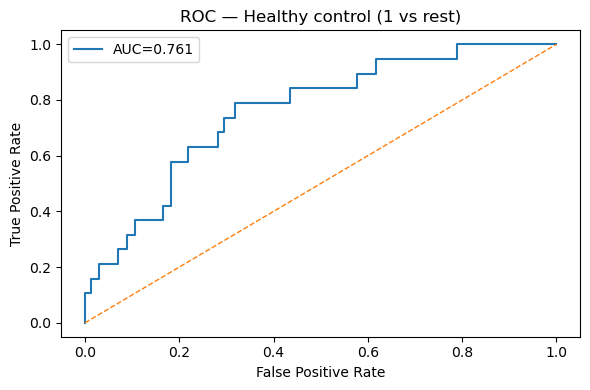

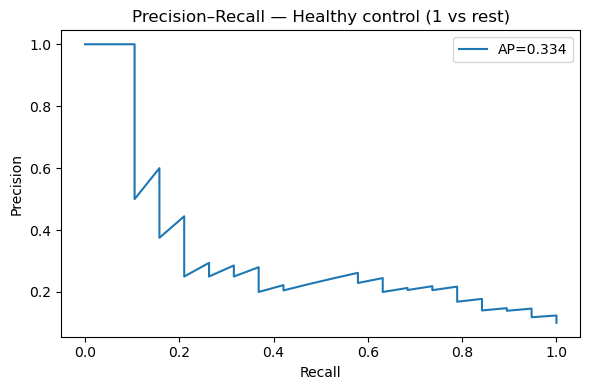

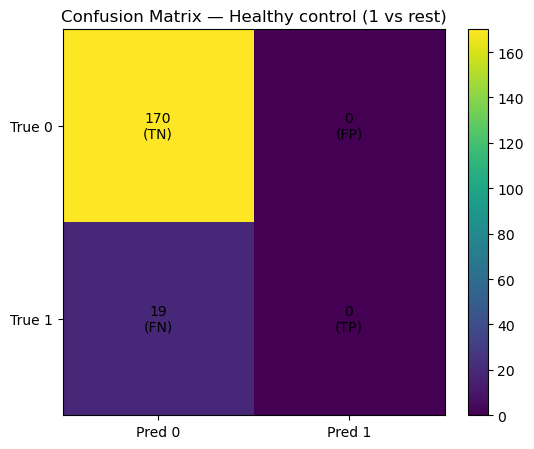

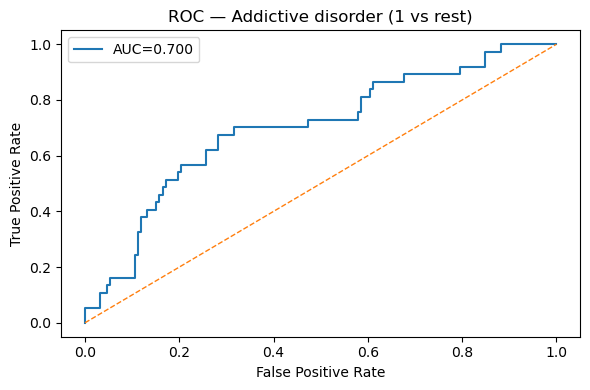

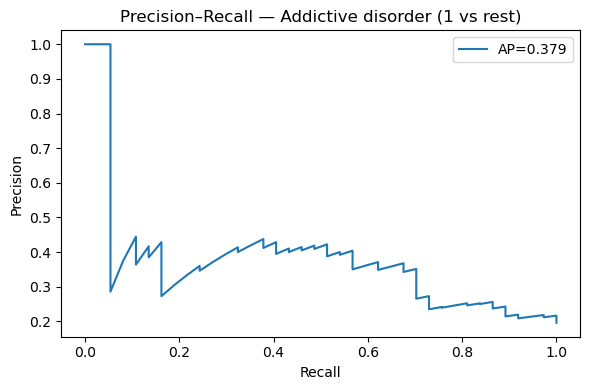

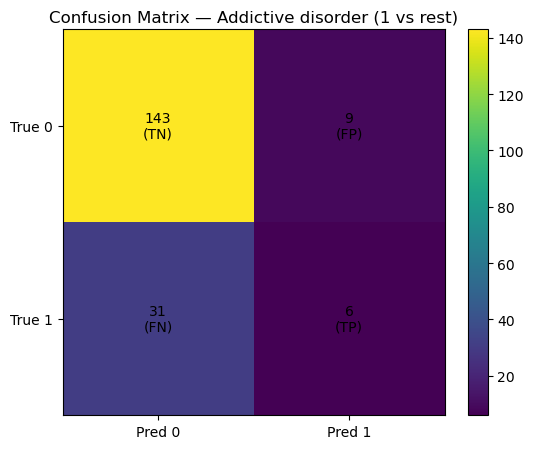

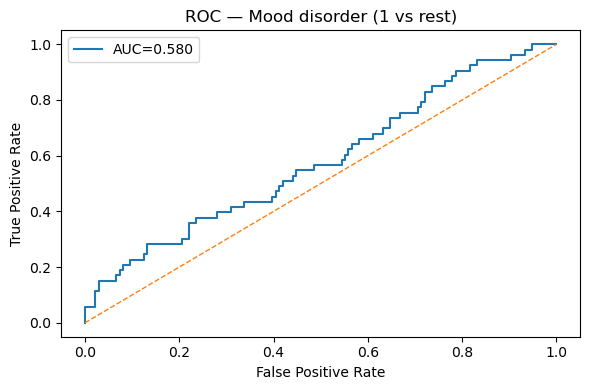

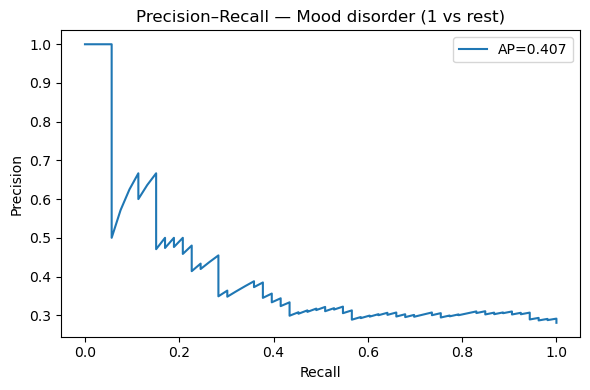

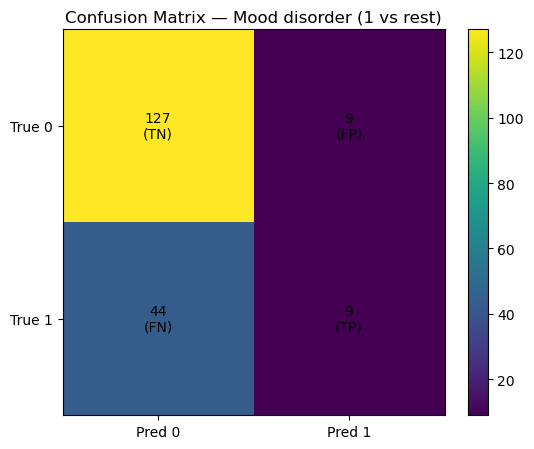

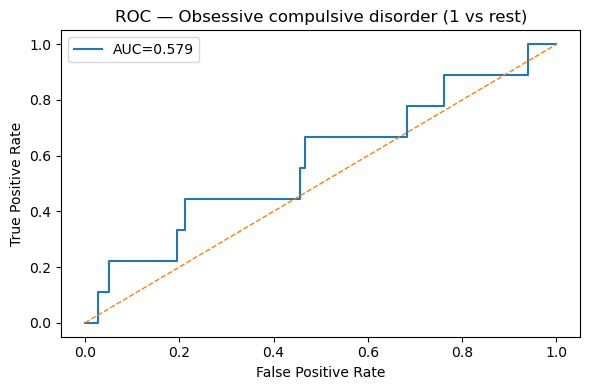

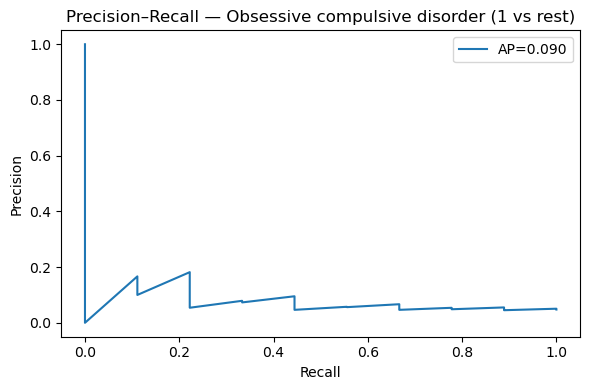

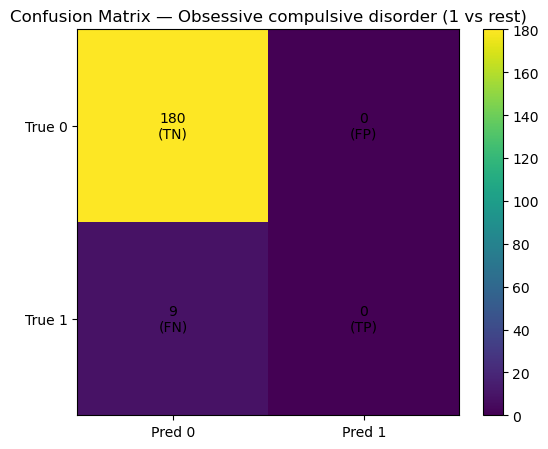

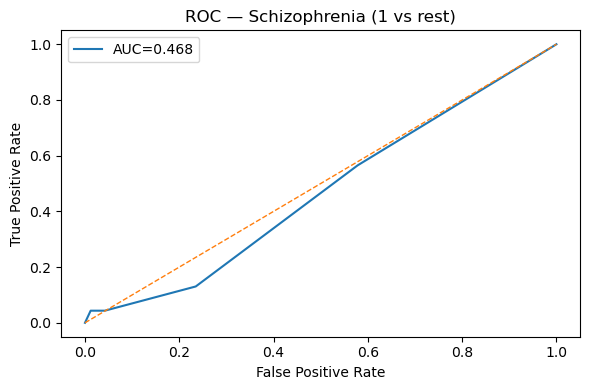

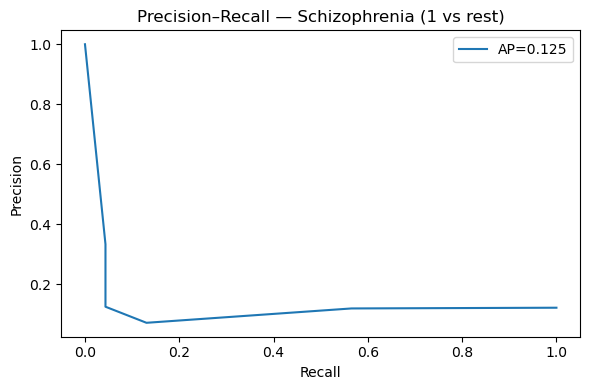

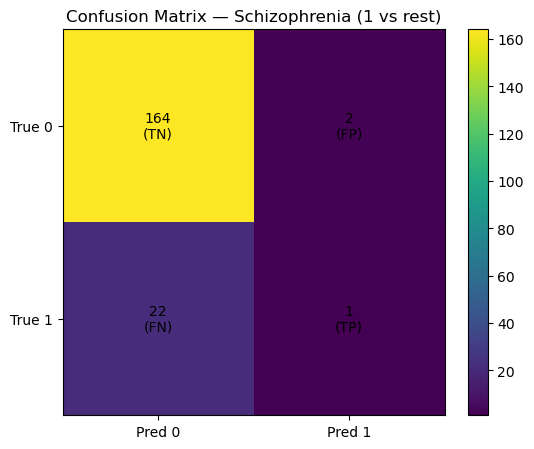

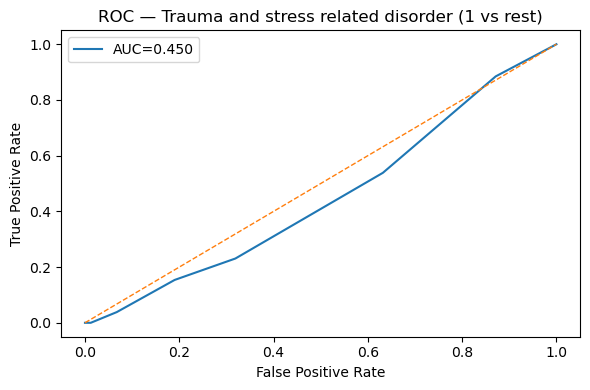

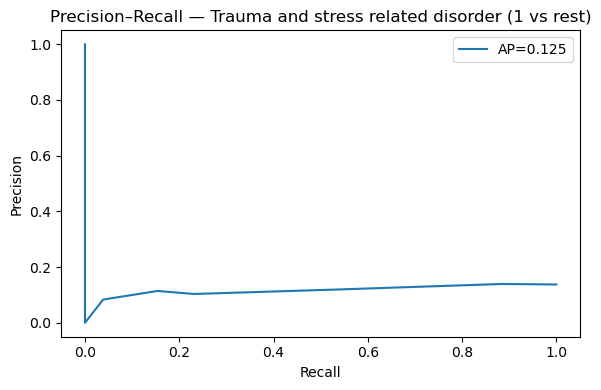

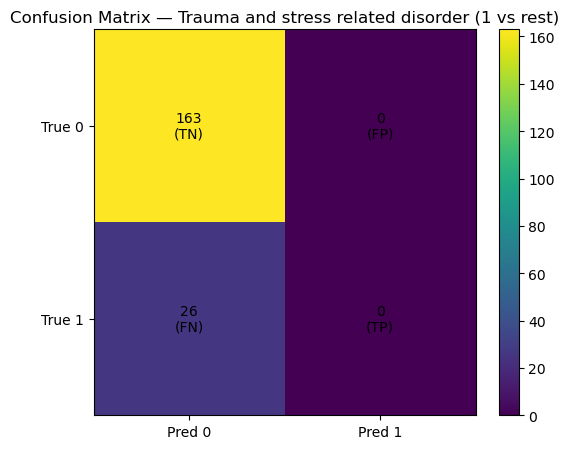

In [ ]:
# ============================================================
# Step 20 — Visualize ROC & PR curves for each condition (optional)
#   (Keeps plots compact by limiting to top 6 by test ROC AUC)
# ============================================================
top_k = min(6, len(per_label_df))
top_conditions = per_label_df.head(top_k)["condition"].tolist()

for cond in top_conditions:
    pipeline, (X_tr, X_te, y_tr, y_te) = best_pipelines_by_label[cond]
    if hasattr(pipeline, "predict_proba"):
        y_proba = pipeline.predict_proba(X_te)[:, 1]
    elif hasattr(pipeline, "decision_function"):
        s = pipeline.decision_function(X_te)
        y_proba = (s - s.min()) / (s.max() - s.min() + 1e-12)
    else:
        y_proba = pipeline.predict(X_te).astype(float)
    y_pred = pipeline.predict(X_te)

    # ROC
    fpr, tpr, _ = roc_curve(y_te, y_proba)
    plt.figure(figsize=(6,4))
    plt.plot(fpr, tpr, label=f"AUC={roc_auc_score(y_te, y_proba):.3f}")
    plt.plot([0,1],[0,1],"--", linewidth=1)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC — {cond} (1 vs rest)")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # PR
    prec_curve, rec_curve, _ = precision_recall_curve(y_te, y_proba)
    plt.figure(figsize=(6,4))
    plt.plot(rec_curve, prec_curve, label=f"AP={average_precision_score(y_te, y_proba):.3f}")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"Precision–Recall — {cond} (1 vs rest)")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Confusion matrix
    cm = confusion_matrix(y_te, y_pred, labels=[0,1])
    labels = np.array([["TN","FP"],["FN","TP"]])
    plt.figure(figsize=(5.6,4.6))
    plt.imshow(cm, aspect="auto")
    plt.title(f"Confusion Matrix — {cond} (1 vs rest)")
    plt.colorbar()
    plt.xticks([0,1], ["Pred 0","Pred 1"])
    plt.yticks([0,1], ["True 0","True 1"])
    for (i, j), val in np.ndenumerate(cm):
        plt.text(j, i, f"{val}\n({labels[i,j]})", ha="center", va="center")
    plt.tight_layout()
    plt.show()


[Step 23] Resolved labels:
  Healthy Control -> Healthy control
  Mood Disorder   -> Mood disorder
  Addictive       -> Addictive disorder

[Step 23] SHAP for: Healthy Control  (label='Healthy control')
  SHAP method: TreeExplainer; eval_n=189, bg_n=200, PCs=100


<Figure size 800x600 with 0 Axes>

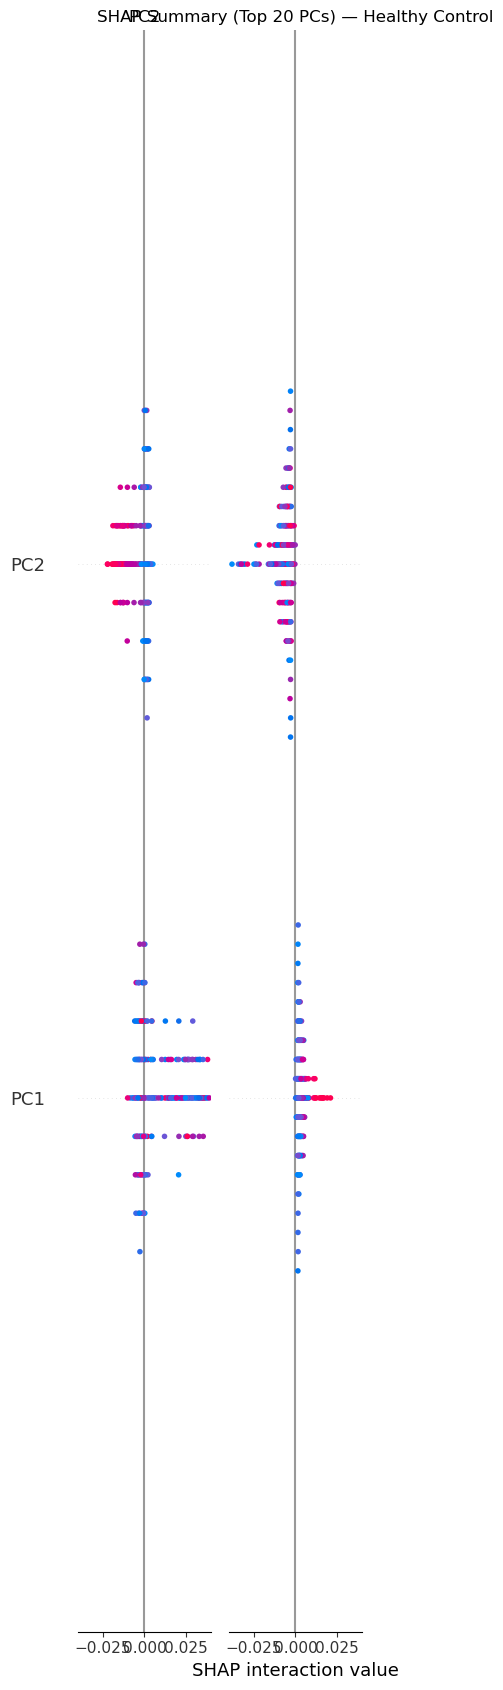

<Figure size 800x600 with 0 Axes>

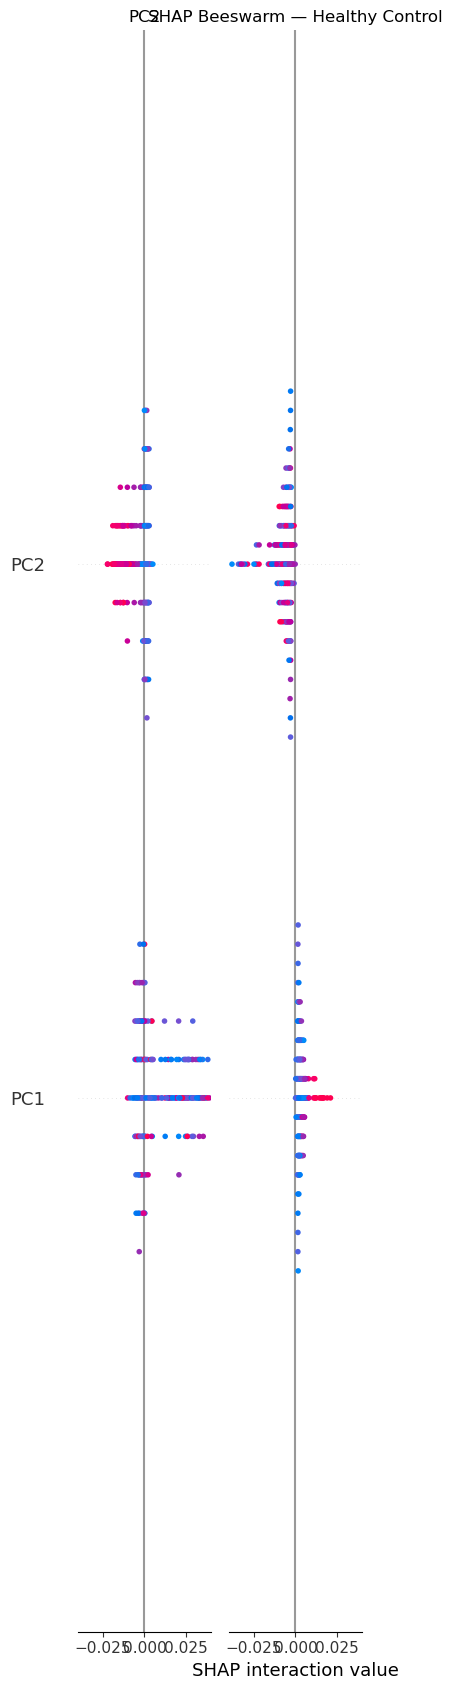


[Step 23] SHAP for: Mood Disorder  (label='Mood disorder')
  SHAP method: TreeExplainer; eval_n=189, bg_n=200, PCs=100


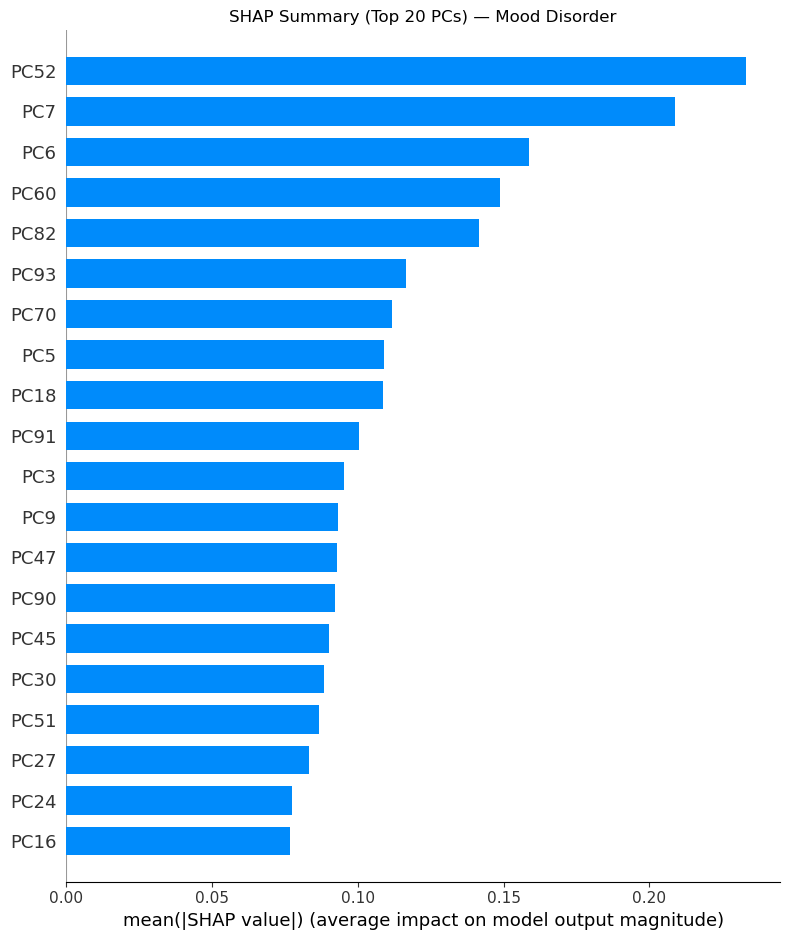

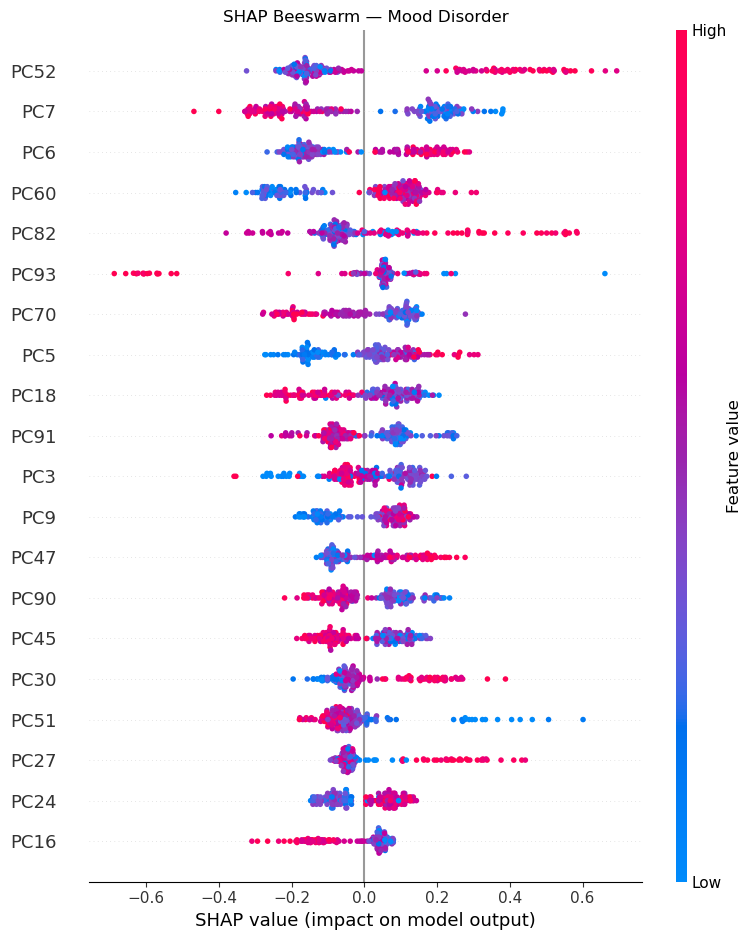


[Step 23] SHAP for: Addictive Disorder  (label='Addictive disorder')
  SHAP method: TreeExplainer; eval_n=189, bg_n=200, PCs=100


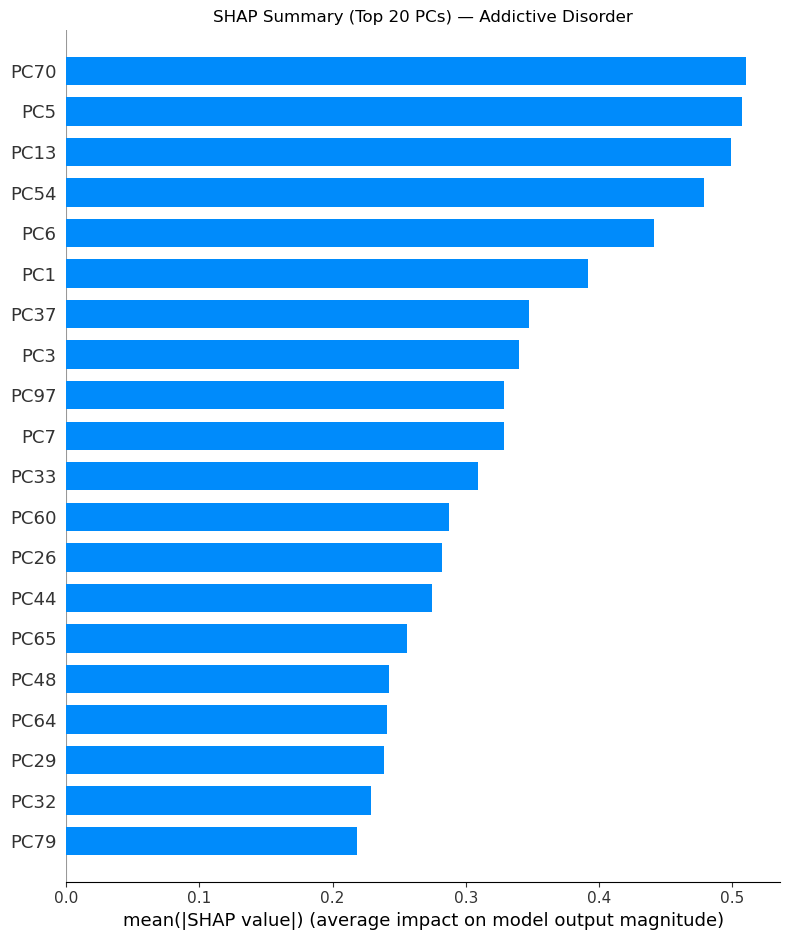

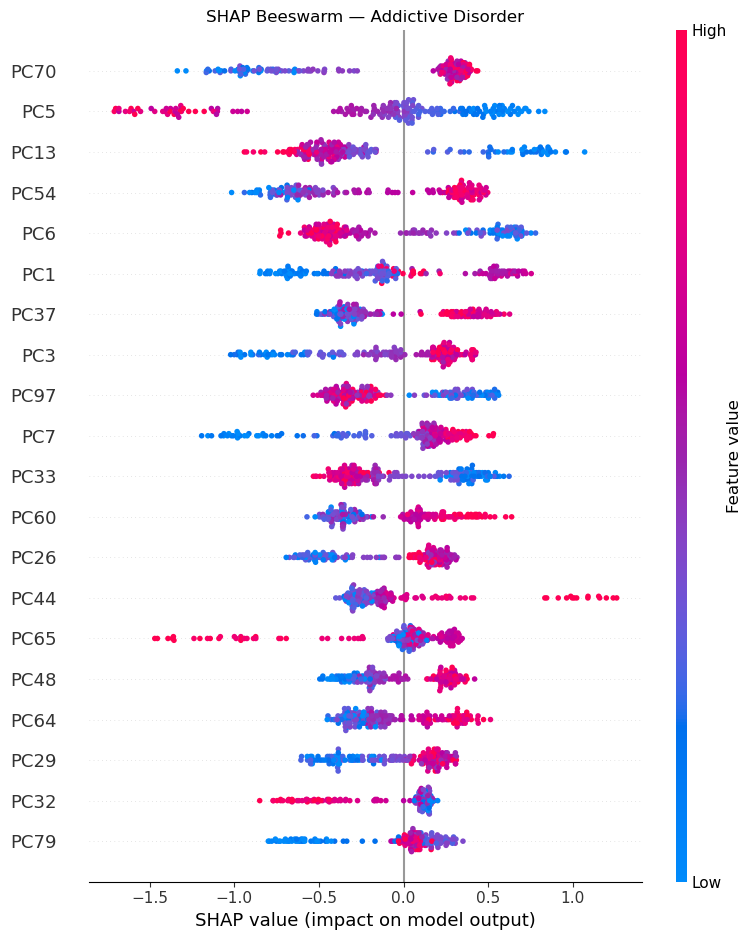

In [ ]:
# ================================================================
# Step 21 — SHAP on Principal Components (Summary Plots)
# ONLY for: Healthy Control, Mood Disorder, Addictive Disorder
# - Reuses fitted per-condition pipelines if available.
# - Otherwise quickly fits a RandomForest pipeline per target.
# - Computes SHAP on PCA inputs and shows bar + beeswarm summaries.
# ================================================================
import sys, subprocess, warnings
warnings.filterwarnings("ignore")

# --- Ensure SHAP is available (no-op if already installed) ---
try:
    import shap  # type: ignore
except Exception:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "shap", "--quiet"])
    import shap  # type: ignore

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# ------------------------------------------------
# Preconditions
# ------------------------------------------------
assert "df" in globals(), "DataFrame `df` not found — run earlier preprocessing cells."
assert "eeg_cols" in globals(), "`eeg_cols` not found — run earlier preprocessing cells."
assert "main.disorder" in df.columns, "`main.disorder` column missing in df."

if "RANDOM_STATE" not in globals():
    RANDOM_STATE = 42

# ------------------------------------------------
# Helper: fuzzy match disorder label by keywords
# ------------------------------------------------
def find_label_by_keywords(keywords, labels):
    """
    Returns the first label that contains ANY of the keywords (case-insensitive).
    Example keywords: ["healthy", "control"]
    """
    labs = list(labels)
    low = [str(x).strip().lower() for x in labs]
    for i, s in enumerate(low):
        if any(k in s for k in keywords):
            return labs[i]
    return None

# ------------------------------------------------
# Resolve the three target conditions present in your data
# ------------------------------------------------
all_labels = df["main.disorder"].astype(str).str.strip().unique().tolist()

label_healthy = find_label_by_keywords(["healthy", "control", "hc"], all_labels)
label_mood    = find_label_by_keywords(["mood", "depress", "bipolar", "unipolar", "mdd"], all_labels)
label_addict  = find_label_by_keywords(["addict", "substance", "alcohol", "sud", "use"], all_labels)

print("[Step 23] Resolved labels:")
print("  Healthy Control ->", label_healthy)
print("  Mood Disorder   ->", label_mood)
print("  Addictive       ->", label_addict)

targets = [("Healthy Control", label_healthy),
           ("Mood Disorder", label_mood),
           ("Addictive Disorder", label_addict)]
targets = [(disp, lab) for disp, lab in targets if lab is not None]

if not targets:
    raise ValueError("Could not match any of the requested categories in df['main.disorder'].")

# ------------------------------------------------
# Helper: get a fitted pipeline for ONE-VS-REST of the given label
# Priority:
#   1) reuse best_pipelines_by_label[label] if it exists (from Steps 19/21)
#   2) else fit a quick RandomForest pipeline for this label
# ------------------------------------------------
def get_or_fit_pipeline_for_label(label):
    global best_pipelines_by_label  # may or may not exist
    if "best_pipelines_by_label" in globals() and label in best_pipelines_by_label:
        pipe, data_tuple = best_pipelines_by_label[label]
        return pipe, data_tuple  # (X_tr, X_te, y_tr, y_te)

    # Fallback quick fit (RandomForest) if not previously trained:
    X = df[eeg_cols].copy()
    y = (df["main.disorder"].astype(str).str.strip() == label).astype(int).values

    # Guard against too-small classes
    pos, neg = int(y.sum()), int(len(y) - y.sum())
    if pos < 5 or neg < 5:
        raise ValueError(f"Label '{label}' has too few samples for a stable split (pos={pos}, neg={neg}).")

    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
    )

    n_comp = int(min(100, X_tr.shape[1], X_tr.shape[0]))

    pipe = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler",  StandardScaler()),
        ("pca",     PCA(n_components=n_comp, svd_solver="randomized", random_state=RANDOM_STATE)),
        ("clf",     RandomForestClassifier(
            n_estimators=800,
            max_depth=None,
            min_samples_leaf=1,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
    pipe.fit(X_tr, y_tr)
    return pipe, (X_tr, X_te, y_tr, y_te)

# ------------------------------------------------
# Helper: Prepare PCA dataframes from pipeline
# ------------------------------------------------
def transform_to_pca_frames(pipe, X_tr, X_te):
    pim = pipe.named_steps["imputer"]
    psc = pipe.named_steps["scaler"]
    pca = pipe.named_steps["pca"]
    X_tr_pca = pca.transform(psc.transform(pim.transform(X_tr)))
    X_te_pca = pca.transform(psc.transform(pim.transform(X_te)))
    labels = [f"PC{i+1}" for i in range(pca.n_components_)]
    return pd.DataFrame(X_tr_pca, columns=labels), pd.DataFrame(X_te_pca, columns=labels), pca

# ------------------------------------------------
# SHAP Summary Plots for the three requested categories
# ------------------------------------------------
for display_name, label in targets:
    print(f"\n[Step 23] SHAP for: {display_name}  (label='{label}')")
    try:
        pipe, (X_tr, X_te, y_tr, y_te) = get_or_fit_pipeline_for_label(label)
    except Exception as e:
        print(f"  Skipping '{display_name}' due to: {e}")
        continue

    # Transform to PCA space used by the model
    X_tr_pca_df, X_te_pca_df, pca = transform_to_pca_frames(pipe, X_tr, X_te)

    # Use a reasonably sized evaluation and background set to keep runtime snappy
    eval_df = X_te_pca_df.sample(n=min(400, len(X_te_pca_df)), random_state=RANDOM_STATE)
    bg_df   = X_tr_pca_df.sample(n=min(200, len(X_tr_pca_df)), random_state=RANDOM_STATE)

    clf = pipe.named_steps["clf"]

    # Prefer TreeExplainer for RandomForest (fast, accurate). Fallback to KernelExplainer otherwise.
    try:
        explainer = shap.TreeExplainer(clf, feature_perturbation="interventional")
        sv = explainer.shap_values(eval_df)
        # If list (class-wise), select class 1 SHAP values (positive class = this disorder)
        shap_vals = sv[1] if isinstance(sv, list) and len(sv) >= 2 else sv
        method_used = "TreeExplainer"
    except Exception:
        # Generic fallback (slower). Use small nsamples to keep things moving.
        f = (lambda X_: clf.predict_proba(X_)[:, 1]) if hasattr(clf, "predict_proba") \
            else (lambda X_: clf.decision_function(X_))
        explainer = shap.KernelExplainer(f, bg_df, link="logit")
        shap_vals = explainer.shap_values(eval_df, nsamples=200)
        method_used = "KernelExplainer"

    print(f"  SHAP method: {method_used}; eval_n={len(eval_df)}, bg_n={len(bg_df)}, PCs={eval_df.shape[1]}")

    # ---- Summary Bar (Top 20 PCs) ----
    plt.figure(figsize=(8,6))
    shap.summary_plot(shap_vals, eval_df, plot_type="bar", max_display=20, show=False)
    plt.title(f"SHAP Summary (Top 20 PCs) — {display_name}")
    plt.tight_layout()
    plt.show()

    # ---- Beeswarm (Top 20 PCs) ----
    plt.figure(figsize=(8,6))
    shap.summary_plot(shap_vals, eval_df, max_display=20, show=False)
    plt.title(f"SHAP Beeswarm — {display_name}")
    plt.tight_layout()
    plt.show()


[PC Drill] Using PCA from pipeline: best_rf_pipeline
 - n_components = 100, n_features = 1140

Top +20 contributors to PC70:


,PC70_loading
COH.D.beta.n.P3.o.Pz,0.172213
COH.E.highbeta.n.P3.o.Pz,0.137571
COH.F.gamma.n.P3.o.Pz,0.115031
COH.C.alpha.n.P3.o.Pz,0.101384
COH.B.theta.o.Pz.r.O1,0.099473
COH.B.theta.c.F7.h.T3,0.093626
COH.D.beta.o.Pz.r.O1,0.093398
COH.B.theta.n.P3.o.Pz,0.093307
COH.E.highbeta.a.FP1.b.FP2,0.087614
COH.C.alpha.k.C4.p.P4,0.086576



Top -20 contributors to PC70:


,PC70_loading
COH.C.alpha.r.O1.s.O2,-0.100716
COH.A.delta.a.FP1.c.F7,-0.092217
COH.C.alpha.i.C3.n.P3,-0.091940
COH.C.alpha.l.T4.o.Pz,-0.090533
AB.A.delta.b.FP2,-0.088373
COH.C.alpha.p.P4.r.O1,-0.080979
COH.C.alpha.j.Cz.n.P3,-0.077856
COH.C.alpha.p.P4.q.T6,-0.074591
COH.C.alpha.k.C4.o.Pz,-0.073074
COH.C.alpha.f.F4.n.P3,-0.072521


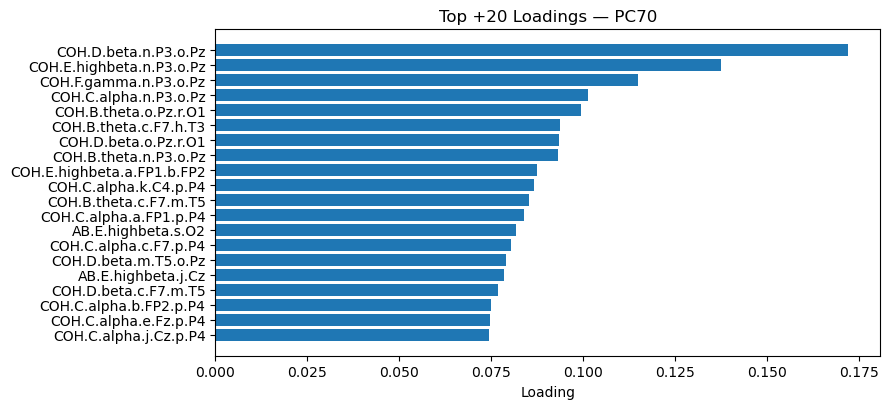

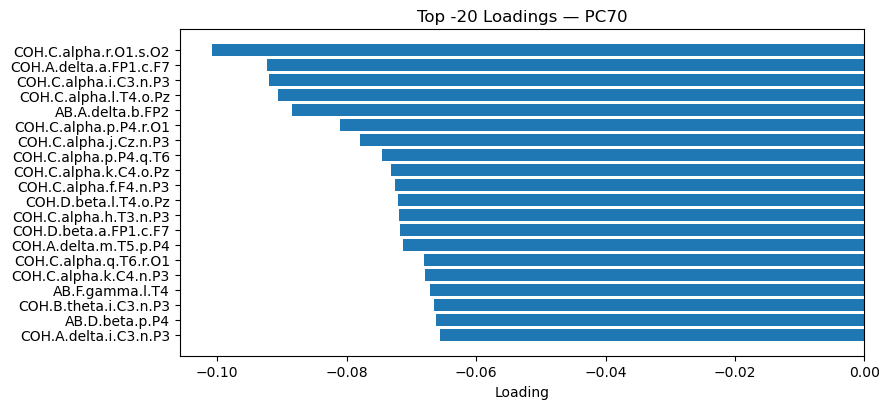


Top +20 contributors to PC52:


,PC52_loading
COH.B.theta.a.FP1.b.FP2,0.112836
COH.B.theta.a.FP1.e.Fz,0.094362
COH.A.delta.h.T3.m.T5,0.092820
COH.A.delta.a.FP1.h.T3,0.088309
COH.A.delta.a.FP1.b.FP2,0.088088
COH.C.alpha.h.T3.m.T5,0.085364
COH.B.theta.h.T3.m.T5,0.083113
COH.B.theta.k.C4.o.Pz,0.081004
COH.B.theta.b.FP2.e.Fz,0.080367
COH.B.theta.a.FP1.f.F4,0.080064



Top -20 contributors to PC52:


,PC52_loading
COH.C.alpha.m.T5.r.O1,-0.100751
COH.E.highbeta.b.FP2.f.F4,-0.090929
COH.F.gamma.b.FP2.f.F4,-0.083558
COH.A.delta.f.F4.g.F8,-0.081510
AB.D.beta.h.T3,-0.079684
COH.F.gamma.m.T5.n.P3,-0.076541
COH.E.highbeta.m.T5.n.P3,-0.076427
AB.D.beta.c.F7,-0.072435
COH.D.beta.f.F4.k.C4,-0.068888
COH.F.gamma.a.FP1.b.FP2,-0.068131


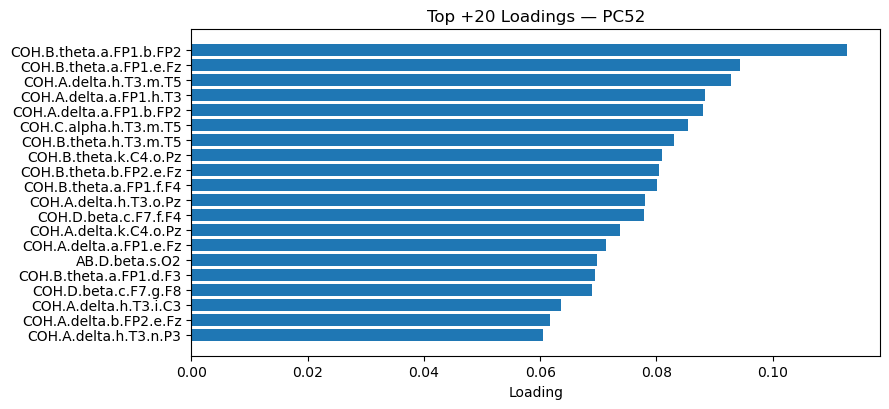

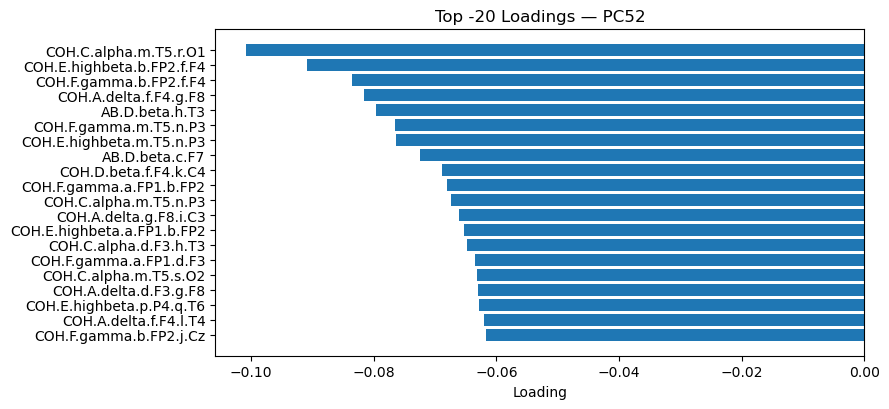


[Model→Original] Top 25 original EEG features driven by (PC70, PC52) via model PC-importance:


,importance
COH.D.beta.n.P3.o.Pz,0.015001
COH.E.highbeta.n.P3.o.Pz,0.009824
COH.B.theta.a.FP1.b.FP2,0.007349
COH.F.gamma.n.P3.o.Pz,0.006777
COH.E.highbeta.a.FP1.b.FP2,0.005989
COH.C.alpha.r.O1.s.O2,0.005574
COH.C.alpha.n.P3.o.Pz,0.005565
COH.C.alpha.m.T5.r.O1,0.005040
COH.B.theta.o.Pz.r.O1,0.005029
AB.E.highbeta.s.O2,0.004913


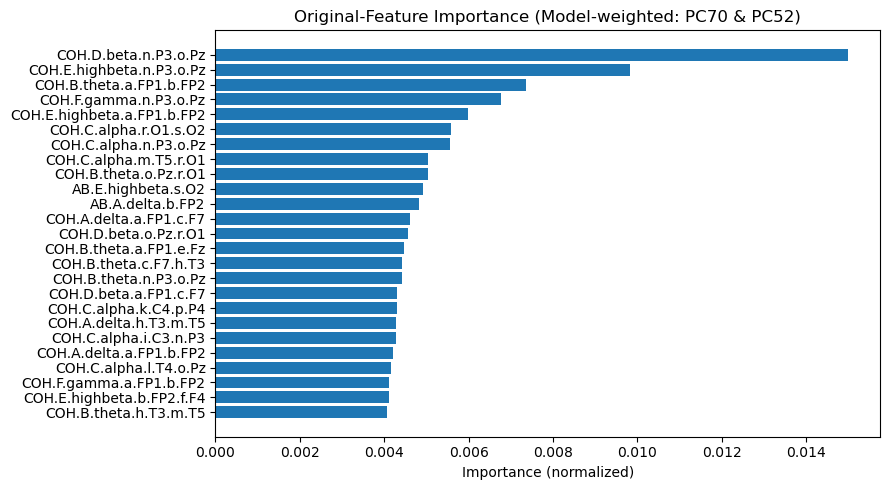

[Info] Could not compute SHAP→original mapping for selected PCs: Mismatch: SHAP n_features vs eval_df n_columns.


In [ ]:
# ================================================================
# Step 22 - Drill into specific PCs (PC70 and PC52): loadings & raw-feature drivers
#
# What this cell does:
#  1) Finds a fitted pipeline with a PCA step (best_rf_pipeline / best_pipeline / patient_pipe).
#  2) Shows top positive/negative loadings for PC70 and PC52 (tables + bar plots).
#  3) (Optional) If model exposes importance over PCs, maps that importance back to original EEG features.
#  4) (Optional) If you computed SHAP on PCs (variables: `shap_vals`, `eval_df`), it also maps SHAP PC-importance
#     back to original EEG features (and can focus on PC70 / PC52 specifically).
#
# Prereqs:
#  - `df` DataFrame is loaded, `eeg_cols` list is defined.
#  - A fitted pipeline with steps ["imputer","scaler","pca","clf"] already exists in one of:
#      - best_rf_pipeline (from tuned RF),
#      - best_pipeline (from model selection),
#      - patient_pipe (from Step 24).
#  - (Optional) `shap_vals` and `eval_df` (PC dataframe used for SHAP) exist for SHAP back-projection.
# ================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Optional, Tuple
from IPython.display import display

# -------------------------------
# 0) Locate a fitted PCA to use
# -------------------------------
def _get_any_fitted_pipeline():
    for name in ["best_rf_pipeline", "best_pipeline", "patient_pipe"]:
        if name in globals():
            pipe = globals()[name]
            if hasattr(pipe, "named_steps") and "pca" in pipe.named_steps:
                return pipe, name
    raise ValueError("No fitted pipeline with a PCA step was found. "
                     "Please run an earlier modeling step to create one (e.g., Steps 10–16 or Step 24).")

pipe, pipe_name = _get_any_fitted_pipeline()
pca = pipe.named_steps["pca"]
feature_names = list(eeg_cols)
assert pca.components_.shape[1] == len(feature_names), "PCA/components mismatch with EEG feature count."

print(f"[PC Drill] Using PCA from pipeline: {pipe_name}")
print(f" - n_components = {pca.n_components_}, n_features = {len(feature_names)}")

# --------------------------------------------
# 1) Helpers to inspect & plot a single PC
# --------------------------------------------
def pc_index_from_label(pc_id, n_components: int) -> int:
    """Accepts 'PC70' or 70 or 69; returns 0-based index with validation."""
    if isinstance(pc_id, str):
        pc_id = pc_id.strip().upper()
        if pc_id.startswith("PC"):
            idx = int(pc_id.replace("PC", "")) - 1
        else:
            idx = int(pc_id)
            # interpret ≥ n_components as 1-based
            if idx >= n_components:
                idx = idx - 1
    else:
        idx = int(pc_id)
        if idx >= n_components:
            idx = idx - 1
    if not (0 <= idx < n_components):
        raise ValueError(f"Requested PC index {idx} out of range. PCA has {n_components} components.")
    return idx

def get_pc_loading_series(pc_zero_based: int) -> pd.Series:
    vec = pca.components_[pc_zero_based, :]
    return pd.Series(vec, index=feature_names)

def show_pc_top_tables(pc_label, top_n: int = 20) -> Tuple[pd.DataFrame, pd.DataFrame]:
    pc = pc_index_from_label(pc_label, pca.n_components_)
    s = get_pc_loading_series(pc)
    top_pos = s.sort_values(ascending=False).head(top_n).to_frame(name=f"PC{pc+1}_loading")
    top_neg = s.sort_values(ascending=True).head(top_n).to_frame(name=f"PC{pc+1}_loading")
    print(f"\nTop +{top_n} contributors to PC{pc+1}:")
    display(top_pos)
    print(f"\nTop -{top_n} contributors to PC{pc+1}:")
    display(top_neg)
    return top_pos, top_neg

def plot_pc_loadings(pc_label, top_n: int = 20):
    pc = pc_index_from_label(pc_label, pca.n_components_)
    s = get_pc_loading_series(pc)
    top_pos = s.sort_values(ascending=False).head(top_n)
    top_neg = s.sort_values(ascending=True).head(top_n)

    # Positive
    plt.figure(figsize=(9, 4.2))
    plt.barh(range(len(top_pos)), top_pos.values[::-1])
    plt.yticks(range(len(top_pos)), top_pos.index[::-1])
    plt.xlabel("Loading")
    plt.title(f"Top +{top_n} Loadings — PC{pc+1}")
    plt.tight_layout()
    plt.show()

    # Negative
    plt.figure(figsize=(9, 4.2))
    plt.barh(range(len(top_neg)), top_neg.values[::-1])
    plt.yticks(range(len(top_neg)), top_neg.index[::-1])
    plt.xlabel("Loading")
    plt.title(f"Top -{top_n} Loadings — PC{pc+1}")
    plt.tight_layout()
    plt.show()

# --------------------------------------------------------------
# 2) Map PC-level importance back to ORIGINAL features
#    (A) From model feature_importances_ / |coef_| over PCs
#    (B) From SHAP on PCs (if `shap_vals` + `eval_df` available)
# --------------------------------------------------------------
def get_pc_importance_from_model(pipe) -> Optional[np.ndarray]:
    clf = pipe.named_steps["clf"]
    if hasattr(clf, "feature_importances_"):
        imp = np.asarray(clf.feature_importances_, dtype=float)
        return imp
    if hasattr(clf, "coef_"):
        coefs = clf.coef_
        if coefs.ndim > 1:
            coefs = coefs.ravel()
        return np.abs(coefs)
    return None

def get_pc_importance_from_shap(shap_vals, eval_df: pd.DataFrame) -> np.ndarray:
    arr = np.asarray(shap_vals)
    if arr.ndim == 3:
        # If provided as [classes, samples, features], pick positive-class index 1
        arr = arr[1]
    assert arr.ndim == 2, "shap_vals must be (n_samples, n_components) for single-class explanation."
    assert arr.shape[1] == eval_df.shape[1], "Mismatch: SHAP n_features vs eval_df n_columns."
    return np.mean(np.abs(arr), axis=0)

def propagate_pc_importance_to_features(pc_importance: np.ndarray, pca_components: np.ndarray, power: int = 2) -> pd.Series:
    L = pca_components  # (n_components, n_features)
    W = (np.abs(L) ** power)
    weighted = pc_importance[:, None] * W
    feat_scores = weighted.sum(axis=0)
    if feat_scores.sum() > 0:
        feat_scores = feat_scores / feat_scores.sum()
    return pd.Series(feat_scores, index=feature_names).sort_values(ascending=False)

def plot_feature_importance_series(series: pd.Series, top_n: int = 25, title: str = "Original-Feature Importance"):
    top = series.head(top_n)
    plt.figure(figsize=(9, 5))
    plt.barh(range(len(top)), top.values[::-1])
    plt.yticks(range(len(top)), top.index[::-1])
    plt.xlabel("Importance (normalized)")
    plt.title(title)
    plt.tight_layout()
    plt.show()

# --------------------------------------------------------------
# 3) RUN for PC70 and PC52
# --------------------------------------------------------------
targets = ["PC70", "PC52"]

for pc_label in targets:
    # Tables + plots of loadings
    show_pc_top_tables(pc_label, top_n=20)
    plot_pc_loadings(pc_label, top_n=20)

# --------------------------------------------------------------
# 4) OPTIONAL: Back-project model/SHAP importance focusing on PC70 and PC52
#    - If model exposes PC importances, we will create a vector where only the
#      selected PCs carry weight (proportional to their importance), then
#      map to original features.
#    - If SHAP over PCs is available, we do the same using SHAP mean(|value|).
# --------------------------------------------------------------
selected_pc_indices = [pc_index_from_label(x, pca.n_components_) for x in targets]

# (A) From model importance over PCs
pc_imp_model = get_pc_importance_from_model(pipe)
if pc_imp_model is not None and len(pc_imp_model) >= max(selected_pc_indices)+1:
    mask_imp = np.zeros_like(pc_imp_model, dtype=float)
    # weight by model's own PC importances (restricted to selected PCs)
    sel_total = pc_imp_model[selected_pc_indices].sum()
    if sel_total > 0:
        mask_imp[selected_pc_indices] = pc_imp_model[selected_pc_indices] / sel_total
    else:
        # if zeros (unlikely), give equal weight to selected PCs
        mask_imp[selected_pc_indices] = 1.0 / len(selected_pc_indices)
    feat_imp_from_model = propagate_pc_importance_to_features(mask_imp, pca.components_, power=2)
    print("\n[Model→Original] Top 25 original EEG features driven by (PC70, PC52) via model PC-importance:")
    display(feat_imp_from_model.head(25).to_frame("importance"))
    plot_feature_importance_series(feat_imp_from_model, top_n=25,
                                   title="Original-Feature Importance (Model-weighted: PC70 & PC52)")

# (B) From SHAP on PCs (requires `shap_vals` and `eval_df` from your SHAP step)
if "shap_vals" in globals() and "eval_df" in globals():
    try:
        pc_imp_shap = get_pc_importance_from_shap(shap_vals, eval_df)
        mask_imp = np.zeros_like(pc_imp_shap, dtype=float)
        sel_total = pc_imp_shap[selected_pc_indices].sum()
        if sel_total > 0:
            mask_imp[selected_pc_indices] = pc_imp_shap[selected_pc_indices] / sel_total
        else:
            mask_imp[selected_pc_indices] = 1.0 / len(selected_pc_indices)
        feat_imp_from_shap = propagate_pc_importance_to_features(mask_imp, pca.components_, power=2)
        print("\n[SHAP(PC)→Original] Top 25 original EEG features driven by (PC70, PC52) via SHAP PC-importance:")
        display(feat_imp_from_shap.head(25).to_frame("importance"))
        plot_feature_importance_series(feat_imp_from_shap, top_n=25,
                                       title="Original-Feature Importance (SHAP-weighted: PC70 & PC52)")
    except Exception as e:
        print(f"[Info] Could not compute SHAP→original mapping for selected PCs: {e}")
